In [204]:
import pandas as pd
import numpy as np
from pathlib import Path

PROCESSED_PATH = Path("../data/processed")

collisions = pd.read_csv(
    PROCESSED_PATH / "collisions_clean.csv"
)

vehicles = pd.read_csv(
    PROCESSED_PATH / "vehicles_clean.csv"
)

casualties = pd.read_csv(
    PROCESSED_PATH / "casualties_clean.csv"
)

print("Clean datasets loaded successfully!")

print("Collisions:", collisions.shape)
print("Vehicles:", vehicles.shape)
print("Casualties:", casualties.shape)

C:\Users\shiva\AppData\Local\Temp\ipykernel_4248\1524917904.py:11: DtypeWarning: Columns (27: generic_make_model) have mixed types. Specify dtype option on import or set low_memory=False.
  vehicles = pd.read_csv(


Clean datasets loaded successfully!
Collisions: (101525, 61)
Vehicles: (183948, 36)
Casualties: (127883, 29)


In [205]:
severity_counts = (
    collisions["severity_label"]
    .value_counts()
)

severity_percent = (
    collisions["severity_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

severity_summary = pd.DataFrame({
    "collision_count": severity_counts,
    "percentage": severity_percent
})

severity_summary

,collision_count,percentage
severity_label,,
Slight,74881,73.76
Serious,25191,24.81
Fatal,1453,1.43


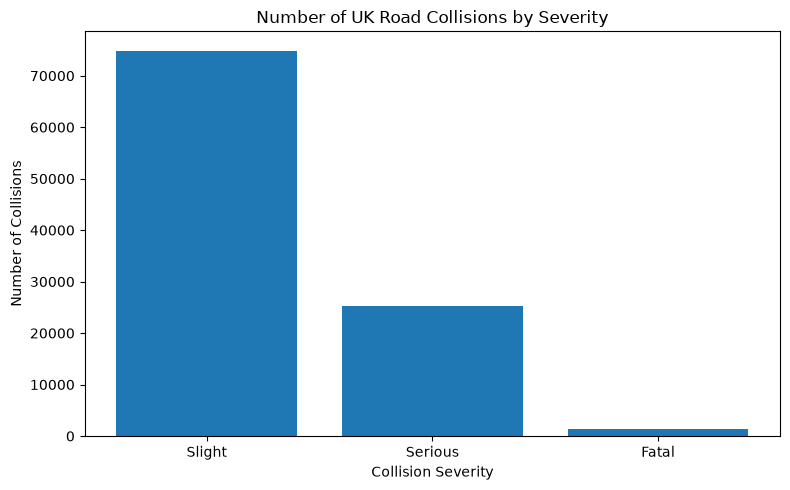

In [206]:
import matplotlib.pyplot as plt

severity_order = ["Slight", "Serious", "Fatal"]

severity_plot = (
    collisions["severity_label"]
    .value_counts()
    .reindex(severity_order)
)

plt.figure(figsize=(8, 5))

plt.bar(
    severity_plot.index,
    severity_plot.values
)

plt.title("Number of UK Road Collisions by Severity")
plt.xlabel("Collision Severity")
plt.ylabel("Number of Collisions")

plt.tight_layout()
plt.show()

In [207]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [208]:
monthly_collisions = (
    collisions
    .groupby(["month", "month_name"])
    .size()
    .reset_index(name="collision_count")
    .sort_values("month")
)

monthly_collisions

,month,month_name,collision_count
0,1,January,8163
1,2,February,7155
2,3,March,8451
3,4,April,8315
4,5,May,8849
5,6,June,8725
6,7,July,8762
7,8,August,8318
8,9,September,8581
9,10,October,8613


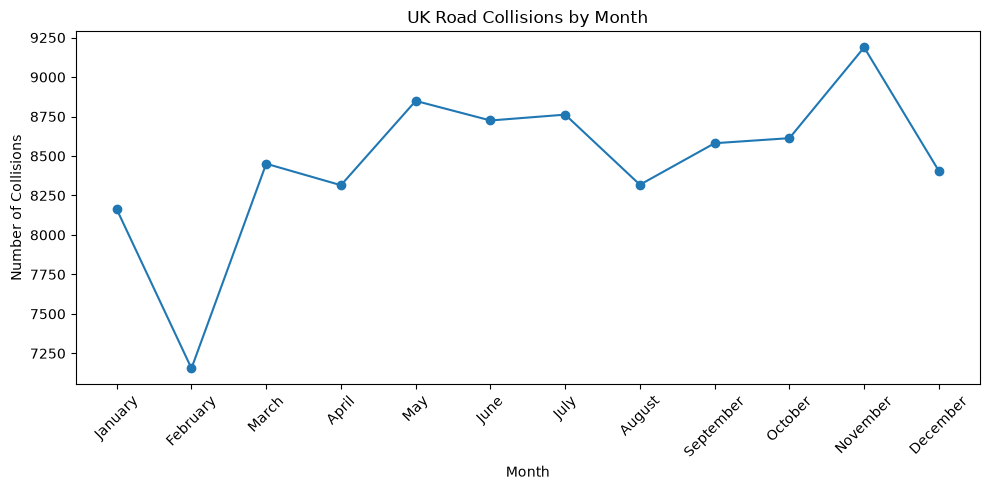

In [209]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_collisions["month_name"],
    monthly_collisions["collision_count"],
    marker="o"
)

plt.title("UK Road Collisions by Month")
plt.xlabel("Month")
plt.ylabel("Number of Collisions")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [210]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

daily_collisions = (
    collisions["day_name"]
    .value_counts()
    .reindex(day_order)
)

daily_collisions

day_name
Monday       14309
Tuesday      14880
Wednesday    15369
Thursday     15304
Friday       16811
Saturday     13655
Sunday       11197
Name: count, dtype: int64

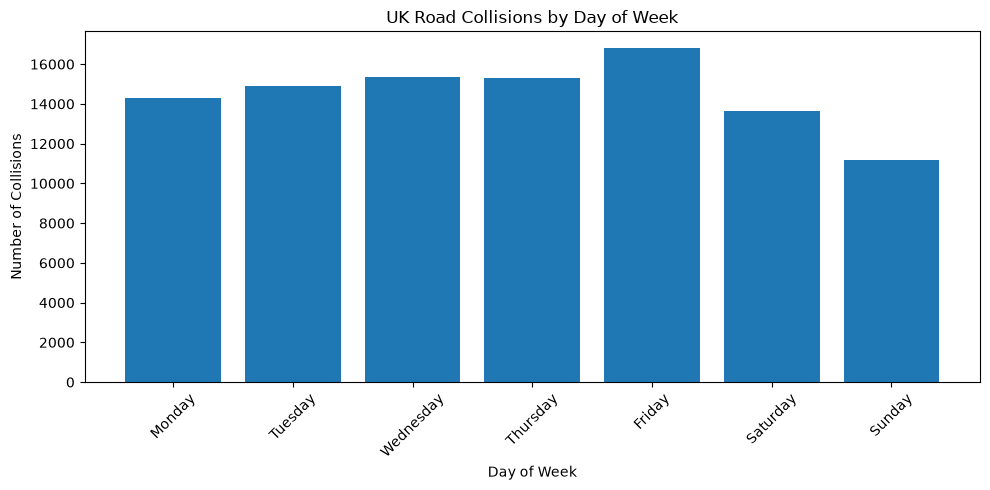

In [211]:
plt.figure(figsize=(10, 5))

plt.bar(
    daily_collisions.index,
    daily_collisions.values
)

plt.title("UK Road Collisions by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Collisions")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [212]:
hourly_collisions = (
    collisions["hour"]
    .value_counts()
    .sort_index()
)

hourly_collisions

hour
0     1525
1     1032
2      789
3      651
4      634
5      952
6     1854
7     4248
8     6716
9     4493
10    4463
11    5069
12    5815
13    6148
14    6466
15    8381
16    8678
17    8877
18    6991
19    5356
20    4022
21    3368
22    2815
23    2182
Name: count, dtype: int64

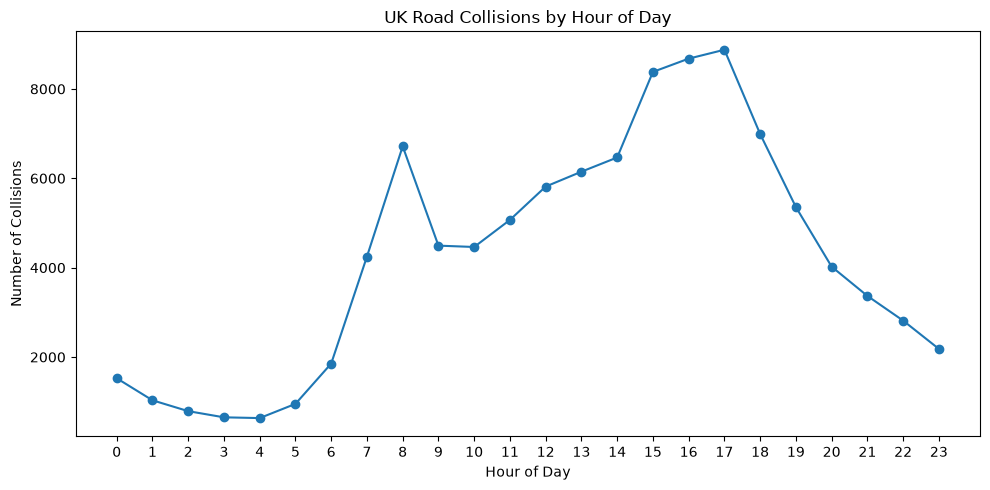

In [213]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_collisions.index,
    hourly_collisions.values,
    marker="o"
)

plt.title("UK Road Collisions by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Collisions")

plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()

In [214]:
time_order = [
    "Morning",
    "Afternoon",
    "Evening",
    "Night"
]

time_of_day_collisions = (
    collisions["time_of_day"]
    .value_counts()
    .reindex(time_order)
)

time_of_day_collisions

time_of_day
Morning      27795
Afternoon    35488
Evening      25246
Night        12996
Name: count, dtype: int64

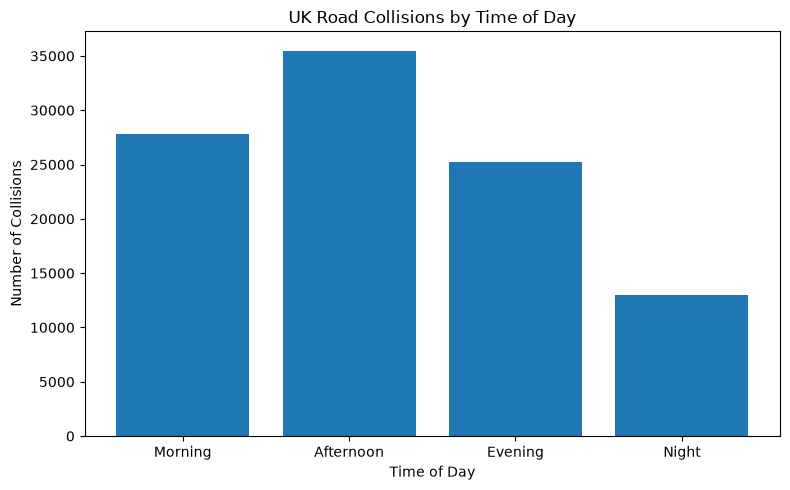

In [215]:
plt.figure(figsize=(8, 5))

plt.bar(
    time_of_day_collisions.index,
    time_of_day_collisions.values
)

plt.title("UK Road Collisions by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Number of Collisions")

plt.tight_layout()
plt.show()

In [216]:
peak_order = [
    "Morning Peak",
    "Evening Peak",
    "Off Peak"
]

peak_collisions = (
    collisions["peak_period"]
    .value_counts()
    .reindex(peak_order)
)

peak_collisions

peak_period
Morning Peak    15457
Evening Peak    24546
Off Peak        61522
Name: count, dtype: int64

In [217]:
hours_in_period = {
    "Morning Peak": 3,
    "Evening Peak": 3,
    "Off Peak": 18
}

peak_summary = peak_collisions.to_frame(
    name="collision_count"
)

peak_summary["hours"] = peak_summary.index.map(
    hours_in_period
)

peak_summary["collisions_per_hour"] = (
    peak_summary["collision_count"]
    / peak_summary["hours"]
).round(2)

peak_summary

,collision_count,hours,collisions_per_hour
peak_period,,,
Morning Peak,15457,3,5152.33
Evening Peak,24546,3,8182.00
Off Peak,61522,18,3417.89


In [218]:
day_type_collisions = (
    collisions["day_type"]
    .value_counts()
)

day_type_collisions

day_type
Weekday    76673
Weekend    24852
Name: count, dtype: int64

In [219]:
days_in_type = {
    "Weekday": 5,
    "Weekend": 2
}

day_type_summary = day_type_collisions.to_frame(
    name="collision_count"
)

day_type_summary["number_of_days"] = (
    day_type_summary.index.map(days_in_type)
)

day_type_summary["average_per_day"] = (
    day_type_summary["collision_count"]
    / day_type_summary["number_of_days"]
).round(2)

day_type_summary

,collision_count,number_of_days,average_per_day
day_type,,,
Weekday,76673,5,15334.6
Weekend,24852,2,12426.0


In [220]:
speed_collisions = (
    collisions["speed_limit"]
    .value_counts()
    .sort_index()
)

speed_collisions

speed_limit
20    20045
30    49673
40     8886
50     4612
60    12709
70     5600
Name: count, dtype: int64

In [221]:
speed_severity = pd.crosstab(
    collisions["speed_limit"],
    collisions["severity_label"]
)

speed_severity

severity_label,Fatal,Serious,Slight
speed_limit,,,
20,103,4378,15564
30,428,11895,37350
40,164,2259,6463
50,114,1250,3248
60,470,4153,8086
70,174,1256,4170


In [222]:
speed_severity_percent = pd.crosstab(
    collisions["speed_limit"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

speed_severity_percent

severity_label,Fatal,Serious,Slight
speed_limit,,,
20,0.51,21.84,77.65
30,0.86,23.95,75.19
40,1.85,25.42,72.73
50,2.47,27.10,70.42
60,3.70,32.68,63.62
70,3.11,22.43,74.46


In [223]:
speed_severity_percent["killed_or_serious_percent"] = (
    speed_severity_percent["Fatal"]
    + speed_severity_percent["Serious"]
)

speed_severity_percent[
    ["Fatal", "Serious", "killed_or_serious_percent"]
]

severity_label,Fatal,Serious,killed_or_serious_percent
speed_limit,,,
20,0.51,21.84,22.35
30,0.86,23.95,24.81
40,1.85,25.42,27.27
50,2.47,27.10,29.57
60,3.70,32.68,36.38
70,3.11,22.43,25.54


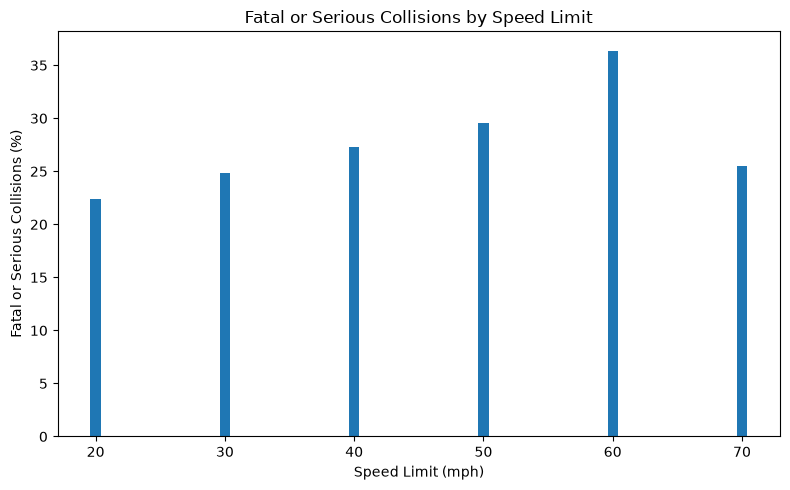

In [224]:
plt.figure(figsize=(8, 5))

plt.bar(
    speed_severity_percent.index,
    speed_severity_percent["killed_or_serious_percent"]
)

plt.title("Fatal or Serious Collisions by Speed Limit")
plt.xlabel("Speed Limit (mph)")
plt.ylabel("Fatal or Serious Collisions (%)")

plt.xticks(speed_severity_percent.index)

plt.tight_layout()
plt.show()

In [225]:
weather_collisions = (
    collisions["weather_label"]
    .value_counts()
)

weather_collisions

weather_label
Fine no high winds       83405
Raining no high winds    10230
Other                     3314
Unknown                   2385
Raining + high winds       880
Fine + high winds          715
Fog or mist                342
Snowing no high winds      235
Snowing + high winds        19
Name: count, dtype: int64

In [226]:
weather_severity = pd.crosstab(
    collisions["weather_label"],
    collisions["severity_label"]
)

weather_severity

severity_label,Fatal,Serious,Slight
weather_label,,,
Fine + high winds,17,213,485
Fine no high winds,1248,21088,61069
Fog or mist,11,99,232
Other,21,668,2625
Raining + high winds,13,234,633
Raining no high winds,138,2528,7564
Snowing + high winds,0,2,17
Snowing no high winds,2,65,168
Unknown,3,294,2088


In [227]:
weather_severity_percent = pd.crosstab(
    collisions["weather_label"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

weather_severity_percent

severity_label,Fatal,Serious,Slight
weather_label,,,
Fine + high winds,2.38,29.79,67.83
Fine no high winds,1.50,25.28,73.22
Fog or mist,3.22,28.95,67.84
Other,0.63,20.16,79.21
Raining + high winds,1.48,26.59,71.93
Raining no high winds,1.35,24.71,73.94
Snowing + high winds,0.00,10.53,89.47
Snowing no high winds,0.85,27.66,71.49
Unknown,0.13,12.33,87.55


In [228]:
weather_severity_percent["killed_or_serious_percent"] = (
    weather_severity_percent["Fatal"]
    + weather_severity_percent["Serious"]
)

weather_severity_percent[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
weather_label,,,
Fine + high winds,2.38,29.79,32.17
Fog or mist,3.22,28.95,32.17
Snowing no high winds,0.85,27.66,28.51
Raining + high winds,1.48,26.59,28.07
Fine no high winds,1.50,25.28,26.78
Raining no high winds,1.35,24.71,26.06
Other,0.63,20.16,20.79
Unknown,0.13,12.33,12.46
Snowing + high winds,0.00,10.53,10.53


In [229]:
surface_collisions = (
    collisions["road_surface_label"]
    .value_counts()
)

surface_collisions

road_surface_label
Dry                             75679
Wet or damp                     22312
Unknown                          1342
Frost or ice                     1261
Data missing or out of range      634
Flood over 3cm deep               151
Snow                              146
Name: count, dtype: int64

In [230]:
surface_severity_percent = pd.crosstab(
    collisions["road_surface_label"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

surface_severity_percent

severity_label,Fatal,Serious,Slight
road_surface_label,,,
Data missing or out of range,0.32,10.25,89.43
Dry,1.42,24.91,73.67
Flood over 3cm deep,2.65,29.80,67.55
Frost or ice,1.43,23.31,75.26
Snow,2.05,27.40,70.55
Unknown,0.00,9.02,90.98
Wet or damp,1.56,25.88,72.56


In [231]:
surface_severity_percent["killed_or_serious_percent"] = (
    surface_severity_percent["Fatal"]
    + surface_severity_percent["Serious"]
)

surface_severity_percent[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
road_surface_label,,,
Flood over 3cm deep,2.65,29.80,32.45
Snow,2.05,27.40,29.45
Wet or damp,1.56,25.88,27.44
Dry,1.42,24.91,26.33
Frost or ice,1.43,23.31,24.74
Data missing or out of range,0.32,10.25,10.57
Unknown,0.00,9.02,9.02


In [232]:
light_collisions = (
    collisions["light_group"]
    .value_counts()
)

light_collisions

light_group
Daylight             72814
Darkness             28695
Unknown / Missing       16
Name: count, dtype: int64

In [233]:
light_severity_percent = pd.crosstab(
    collisions["light_group"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

light_severity_percent

severity_label,Fatal,Serious,Slight
light_group,,,
Darkness,1.99,26.58,71.44
Daylight,1.21,24.12,74.67
Unknown / Missing,0.00,25.00,75.00


In [234]:
light_severity_percent["killed_or_serious_percent"] = (
    light_severity_percent["Fatal"]
    + light_severity_percent["Serious"]
)

light_severity_percent[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
light_group,,,
Darkness,1.99,26.58,28.57
Daylight,1.21,24.12,25.33
Unknown / Missing,0.00,25.00,25.00


In [235]:
area_collisions = (
    collisions["area_type"]
    .value_counts()
)

area_collisions

area_type
Urban          67148
Rural          34373
Unallocated        4
Name: count, dtype: int64

In [236]:
area_severity_percent = pd.crosstab(
    collisions["area_type"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

area_severity_percent

severity_label,Fatal,Serious,Slight
area_type,,,
Rural,2.71,28.17,69.12
Unallocated,0.00,50.00,50.00
Urban,0.78,23.09,76.13


In [237]:
area_severity_percent["killed_or_serious_percent"] = (
    area_severity_percent["Fatal"]
    + area_severity_percent["Serious"]
)

area_severity_percent[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
area_type,,,
Unallocated,0.00,50.00,50.00
Rural,2.71,28.17,30.88
Urban,0.78,23.09,23.87


In [238]:
road_type_collisions = (
    collisions["road_type_label"]
    .value_counts()
)

road_type_collisions

road_type_label
Single carriageway    74150
Dual carriageway      14610
Roundabout             6795
One way street         2398
Unknown                1953
Slip road              1619
Name: count, dtype: int64

In [239]:
road_type_severity_percent = pd.crosstab(
    collisions["road_type_label"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

road_type_severity_percent

severity_label,Fatal,Serious,Slight
road_type_label,,,
Dual carriageway,1.83,22.72,75.44
One way street,0.25,20.31,79.44
Roundabout,0.63,18.84,80.53
Single carriageway,1.51,26.42,72.07
Slip road,1.05,18.96,79.99
Unknown,0.00,10.70,89.30


In [240]:
road_type_severity_percent["killed_or_serious_percent"] = (
    road_type_severity_percent["Fatal"]
    + road_type_severity_percent["Serious"]
)

road_type_severity_percent[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
road_type_label,,,
Single carriageway,1.51,26.42,27.93
Dual carriageway,1.83,22.72,24.55
One way street,0.25,20.31,20.56
Slip road,1.05,18.96,20.01
Roundabout,0.63,18.84,19.47
Unknown,0.00,10.70,10.70


In [241]:
peak_collisions = (
    collisions["peak_period"]
    .value_counts()
)

peak_collisions

peak_period
Off Peak        61522
Evening Peak    24546
Morning Peak    15457
Name: count, dtype: int64

In [242]:
peak_severity_percent = pd.crosstab(
    collisions["peak_period"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

peak_severity_percent

severity_label,Fatal,Serious,Slight
peak_period,,,
Evening Peak,1.08,24.83,74.10
Morning Peak,0.93,21.60,77.47
Off Peak,1.70,25.62,72.69


In [243]:
peak_severity_percent["killed_or_serious_percent"] = (
    peak_severity_percent["Fatal"]
    + peak_severity_percent["Serious"]
)

peak_severity_percent[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
peak_period,,,
Off Peak,1.70,25.62,27.32
Evening Peak,1.08,24.83,25.91
Morning Peak,0.93,21.60,22.53


In [244]:
day_type_severity = pd.crosstab(
    collisions["day_type"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

day_type_severity

severity_label,Fatal,Serious,Slight
day_type,,,
Weekday,1.32,24.21,74.47
Weekend,1.79,26.67,71.54


In [245]:
day_type_severity["killed_or_serious_percent"] = (
    day_type_severity["Fatal"]
    + day_type_severity["Serious"]
)

day_type_severity[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
day_type,,,
Weekend,1.79,26.67,28.46
Weekday,1.32,24.21,25.53


In [246]:
hour_severity = pd.crosstab(
    collisions["hour"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

hour_severity["killed_or_serious_percent"] = (
    hour_severity["Fatal"]
    + hour_severity["Serious"]
)

hour_severity[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
hour,,,
4,3.94,29.18,33.12
1,2.91,29.94,32.85
0,2.75,30.03,32.78
2,2.66,29.66,32.32
3,2.92,28.73,31.65
22,2.31,28.74,31.05
23,2.93,27.50,30.43
21,2.46,27.29,29.75
5,2.63,27.10,29.73


In [247]:
hour_collision_count = (
    collisions["hour"]
    .value_counts()
    .sort_index()
)

hour_analysis = hour_severity[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].copy()

hour_analysis["collision_count"] = hour_collision_count

hour_analysis.sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent,collision_count
hour,,,,
4,3.94,29.18,33.12,634
1,2.91,29.94,32.85,1032
0,2.75,30.03,32.78,1525
2,2.66,29.66,32.32,789
3,2.92,28.73,31.65,651
22,2.31,28.74,31.05,2815
23,2.93,27.50,30.43,2182
21,2.46,27.29,29.75,3368
5,2.63,27.10,29.73,952


In [248]:
hour_analysis.sort_values(
    "collision_count",
    ascending=False
).head(10)

severity_label,Fatal,Serious,killed_or_serious_percent,collision_count
hour,,,,
17,1.14,24.19,25.33,8877
16,0.93,24.53,25.46,8678
15,1.06,24.57,25.63,8381
18,1.17,26.00,27.17,6991
8,0.76,20.61,21.37,6716
14,1.55,24.73,26.28,6466
13,1.17,24.30,25.47,6148
12,1.44,24.92,26.36,5815
19,1.27,25.07,26.34,5356


In [249]:
driver_age_counts = (
    vehicles["driver_age_group"]
    .value_counts()
    .sort_index()
)

driver_age_counts

driver_age_group
0-15      2348
16-19     9475
20-24    16109
25-34    34399
35-44    31121
45-54    24351
55-64    20518
65-74     9792
75+       7573
Name: count, dtype: int64

In [250]:
vehicle_severity = vehicles.merge(
    collisions[["collision_index", "severity_label"]],
    on="collision_index",
    how="left"
)

print("Rows after merge:", len(vehicle_severity))
print("Missing severity labels:", vehicle_severity["severity_label"].isna().sum())

vehicle_severity[
    ["collision_index", "driver_age_group", "severity_label"]
].head()

Rows after merge: 183948
Missing severity labels: 0


,collision_index,driver_age_group,severity_label
0,2025552501020,16-19,Slight
1,2025221557045,16-19,Slight
2,2025221551102,16-19,Slight
3,2025161606443,16-19,Slight
4,2025031672722,25-34,Slight


In [251]:
driver_age_severity = pd.crosstab(
    vehicle_severity["driver_age_group"],
    vehicle_severity["severity_label"],
    normalize="index"
).mul(100).round(2)

driver_age_severity

severity_label,Fatal,Serious,Slight
driver_age_group,,,
0-15,0.64,25.85,73.51
16-19,1.61,29.07,69.32
20-24,1.38,24.74,73.87
25-34,1.26,23.15,75.59
35-44,1.42,23.36,75.22
45-54,1.41,24.17,74.42
55-64,1.93,27.02,71.05
65-74,2.26,29.12,68.63
75+,2.84,29.50,67.66


In [252]:
driver_age_severity["killed_or_serious_percent"] = (
    driver_age_severity["Fatal"]
    + driver_age_severity["Serious"]
)

driver_age_severity[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
driver_age_group,,,
75+,2.84,29.50,32.34
65-74,2.26,29.12,31.38
16-19,1.61,29.07,30.68
55-64,1.93,27.02,28.95
0-15,0.64,25.85,26.49
20-24,1.38,24.74,26.12
45-54,1.41,24.17,25.58
35-44,1.42,23.36,24.78
25-34,1.26,23.15,24.41


In [253]:
casualty_age_counts = (
    casualties["casualty_age_group"]
    .value_counts()
    .sort_index()
)

casualty_age_counts

casualty_age_group
0-15     11579
16-19    10820
20-24    13267
25-34    24761
35-44    20402
45-54    15669
55-64    13893
65-74     7658
75+       7093
Name: count, dtype: int64

In [254]:
print("Casualty severity values:")
print(
    casualties["casualty_severity"]
    .value_counts()
    .sort_index()
)

Casualty severity values:
casualty_severity
1     1538
2    27758
3    98587
Name: count, dtype: int64


In [255]:
casualty_severity_map = {
    1: "Fatal",
    2: "Serious",
    3: "Slight"
}

casualties["casualty_severity_label"] = (
    casualties["casualty_severity"]
    .map(casualty_severity_map)
)

print(
    casualties["casualty_severity_label"]
    .value_counts()
)

print(
    "\nUnmapped values:",
    casualties["casualty_severity_label"].isna().sum()
)

casualty_severity_label
Slight     98587
Serious    27758
Fatal       1538
Name: count, dtype: int64

Unmapped values: 0


In [256]:
casualty_age_severity = pd.crosstab(
    casualties["casualty_age_group"],
    casualties["casualty_severity_label"],
    normalize="index"
).mul(100).round(2)

casualty_age_severity

casualty_severity_label,Fatal,Serious,Slight
casualty_age_group,,,
0-15,0.35,20.10,79.55
16-19,1.22,25.42,73.36
20-24,1.04,21.23,77.73
25-34,0.83,19.01,80.16
35-44,0.91,18.93,80.16
45-54,1.09,20.67,78.24
55-64,1.55,24.82,73.63
65-74,2.18,28.70,69.12
75+,3.98,30.99,65.04


In [257]:
casualty_age_severity["killed_or_serious_percent"] = (
    casualty_age_severity["Fatal"]
    + casualty_age_severity["Serious"]
)

casualty_age_severity[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

casualty_severity_label,Fatal,Serious,killed_or_serious_percent
casualty_age_group,,,
75+,3.98,30.99,34.97
65-74,2.18,28.70,30.88
16-19,1.22,25.42,26.64
55-64,1.55,24.82,26.37
20-24,1.04,21.23,22.27
45-54,1.09,20.67,21.76
0-15,0.35,20.10,20.45
35-44,0.91,18.93,19.84
25-34,0.83,19.01,19.84


In [258]:
casualty_age_summary = pd.DataFrame({
    "casualty_count": casualties["casualty_age_group"].value_counts(),
    "killed_or_serious_percent":
        casualty_age_severity["killed_or_serious_percent"]
})

casualty_age_summary = casualty_age_summary.sort_values(
    "casualty_count",
    ascending=False
)

casualty_age_summary

,casualty_count,killed_or_serious_percent
casualty_age_group,,
25-34,24761,19.84
35-44,20402,19.84
45-54,15669,21.76
55-64,13893,26.37
20-24,13267,22.27
0-15,11579,20.45
16-19,10820,26.64
65-74,7658,30.88
75+,7093,34.97


In [259]:
speed_summary = (
    collisions["speed_limit"]
    .value_counts()
    .sort_index()
)

speed_summary

speed_limit
20    20045
30    49673
40     8886
50     4612
60    12709
70     5600
Name: count, dtype: int64

In [260]:
speed_severity = pd.crosstab(
    collisions["speed_limit"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

speed_severity

severity_label,Fatal,Serious,Slight
speed_limit,,,
20,0.51,21.84,77.65
30,0.86,23.95,75.19
40,1.85,25.42,72.73
50,2.47,27.10,70.42
60,3.70,32.68,63.62
70,3.11,22.43,74.46


In [261]:
speed_severity["killed_or_serious_percent"] = (
    speed_severity["Fatal"]
    + speed_severity["Serious"]
)

speed_severity[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
speed_limit,,,
60,3.70,32.68,36.38
50,2.47,27.10,29.57
40,1.85,25.42,27.27
70,3.11,22.43,25.54
30,0.86,23.95,24.81
20,0.51,21.84,22.35


In [262]:
road_type_summary = (
    collisions["road_type_label"]
    .value_counts()
)

road_type_summary

road_type_label
Single carriageway    74150
Dual carriageway      14610
Roundabout             6795
One way street         2398
Unknown                1953
Slip road              1619
Name: count, dtype: int64

In [263]:
road_type_severity = pd.crosstab(
    collisions["road_type_label"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

road_type_severity

severity_label,Fatal,Serious,Slight
road_type_label,,,
Dual carriageway,1.83,22.72,75.44
One way street,0.25,20.31,79.44
Roundabout,0.63,18.84,80.53
Single carriageway,1.51,26.42,72.07
Slip road,1.05,18.96,79.99
Unknown,0.00,10.70,89.30


In [264]:
road_type_severity["killed_or_serious_percent"] = (
    road_type_severity["Fatal"]
    + road_type_severity["Serious"]
)

road_type_severity[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
road_type_label,,,
Single carriageway,1.51,26.42,27.93
Dual carriageway,1.83,22.72,24.55
One way street,0.25,20.31,20.56
Slip road,1.05,18.96,20.01
Roundabout,0.63,18.84,19.47
Unknown,0.00,10.70,10.70


In [265]:
weather_summary = (
    collisions["weather_label"]
    .value_counts()
)

weather_summary

weather_label
Fine no high winds       83405
Raining no high winds    10230
Other                     3314
Unknown                   2385
Raining + high winds       880
Fine + high winds          715
Fog or mist                342
Snowing no high winds      235
Snowing + high winds        19
Name: count, dtype: int64

In [266]:
weather_severity = pd.crosstab(
    collisions["weather_label"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

weather_severity

severity_label,Fatal,Serious,Slight
weather_label,,,
Fine + high winds,2.38,29.79,67.83
Fine no high winds,1.50,25.28,73.22
Fog or mist,3.22,28.95,67.84
Other,0.63,20.16,79.21
Raining + high winds,1.48,26.59,71.93
Raining no high winds,1.35,24.71,73.94
Snowing + high winds,0.00,10.53,89.47
Snowing no high winds,0.85,27.66,71.49
Unknown,0.13,12.33,87.55


In [267]:
weather_severity["killed_or_serious_percent"] = (
    weather_severity["Fatal"]
    + weather_severity["Serious"]
)

weather_analysis = weather_severity[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].copy()

weather_analysis["collision_count"] = (
    collisions["weather_label"].value_counts()
)

weather_analysis.sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent,collision_count
weather_label,,,,
Fine + high winds,2.38,29.79,32.17,715
Fog or mist,3.22,28.95,32.17,342
Snowing no high winds,0.85,27.66,28.51,235
Raining + high winds,1.48,26.59,28.07,880
Fine no high winds,1.50,25.28,26.78,83405
Raining no high winds,1.35,24.71,26.06,10230
Other,0.63,20.16,20.79,3314
Unknown,0.13,12.33,12.46,2385
Snowing + high winds,0.00,10.53,10.53,19


In [268]:
reliable_weather = weather_analysis[
    weather_analysis["collision_count"] >= 500
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

reliable_weather

severity_label,Fatal,Serious,killed_or_serious_percent,collision_count
weather_label,,,,
Fine + high winds,2.38,29.79,32.17,715
Raining + high winds,1.48,26.59,28.07,880
Fine no high winds,1.50,25.28,26.78,83405
Raining no high winds,1.35,24.71,26.06,10230
Other,0.63,20.16,20.79,3314
Unknown,0.13,12.33,12.46,2385


In [269]:
light_summary = (
    collisions["light_group"]
    .value_counts()
)

light_summary

light_group
Daylight             72814
Darkness             28695
Unknown / Missing       16
Name: count, dtype: int64

In [270]:
light_severity = pd.crosstab(
    collisions["light_group"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

light_severity

severity_label,Fatal,Serious,Slight
light_group,,,
Darkness,1.99,26.58,71.44
Daylight,1.21,24.12,74.67
Unknown / Missing,0.00,25.00,75.00


In [271]:
light_severity["killed_or_serious_percent"] = (
    light_severity["Fatal"]
    + light_severity["Serious"]
)

light_severity[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
light_group,,,
Darkness,1.99,26.58,28.57
Daylight,1.21,24.12,25.33
Unknown / Missing,0.00,25.00,25.00


In [272]:
surface_summary = (
    collisions["road_surface_label"]
    .value_counts()
)

surface_summary

road_surface_label
Dry                             75679
Wet or damp                     22312
Unknown                          1342
Frost or ice                     1261
Data missing or out of range      634
Flood over 3cm deep               151
Snow                              146
Name: count, dtype: int64

In [273]:
surface_severity = pd.crosstab(
    collisions["road_surface_label"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

surface_severity

severity_label,Fatal,Serious,Slight
road_surface_label,,,
Data missing or out of range,0.32,10.25,89.43
Dry,1.42,24.91,73.67
Flood over 3cm deep,2.65,29.80,67.55
Frost or ice,1.43,23.31,75.26
Snow,2.05,27.40,70.55
Unknown,0.00,9.02,90.98
Wet or damp,1.56,25.88,72.56


In [274]:
surface_severity["killed_or_serious_percent"] = (
    surface_severity["Fatal"]
    + surface_severity["Serious"]
)

surface_analysis = surface_severity.copy()

surface_analysis["collision_count"] = (
    collisions["road_surface_label"].value_counts()
)

surface_analysis[
    ["Fatal", "Serious", "killed_or_serious_percent", "collision_count"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent,collision_count
road_surface_label,,,,
Flood over 3cm deep,2.65,29.80,32.45,151
Snow,2.05,27.40,29.45,146
Wet or damp,1.56,25.88,27.44,22312
Dry,1.42,24.91,26.33,75679
Frost or ice,1.43,23.31,24.74,1261
Data missing or out of range,0.32,10.25,10.57,634
Unknown,0.00,9.02,9.02,1342


In [275]:
area_summary = (
    collisions["area_type"]
    .value_counts()
)

area_summary

area_type
Urban          67148
Rural          34373
Unallocated        4
Name: count, dtype: int64

In [276]:
area_severity = pd.crosstab(
    collisions["area_type"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

area_severity

severity_label,Fatal,Serious,Slight
area_type,,,
Rural,2.71,28.17,69.12
Unallocated,0.00,50.00,50.00
Urban,0.78,23.09,76.13


In [277]:
area_severity["killed_or_serious_percent"] = (
    area_severity["Fatal"]
    + area_severity["Serious"]
)

area_severity[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
area_type,,,
Unallocated,0.00,50.00,50.00
Rural,2.71,28.17,30.88
Urban,0.78,23.09,23.87


In [278]:
peak_summary = (
    collisions["peak_period"]
    .value_counts()
)

peak_summary

peak_period
Off Peak        61522
Evening Peak    24546
Morning Peak    15457
Name: count, dtype: int64

In [279]:
peak_severity = pd.crosstab(
    collisions["peak_period"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

peak_severity

severity_label,Fatal,Serious,Slight
peak_period,,,
Evening Peak,1.08,24.83,74.10
Morning Peak,0.93,21.60,77.47
Off Peak,1.70,25.62,72.69


In [280]:
peak_severity["killed_or_serious_percent"] = (
    peak_severity["Fatal"]
    + peak_severity["Serious"]
)

peak_severity[
    ["Fatal", "Serious", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,killed_or_serious_percent
peak_period,,,
Off Peak,1.70,25.62,27.32
Evening Peak,1.08,24.83,25.91
Morning Peak,0.93,21.60,22.53


In [281]:
import matplotlib.pyplot as plt

print("Matplotlib loaded successfully!")

Matplotlib loaded successfully!


In [282]:
import seaborn as sns

print("Seaborn version:", sns.__version__)
print("Seaborn loaded successfully!")

Seaborn version: 0.13.2
Seaborn loaded successfully!


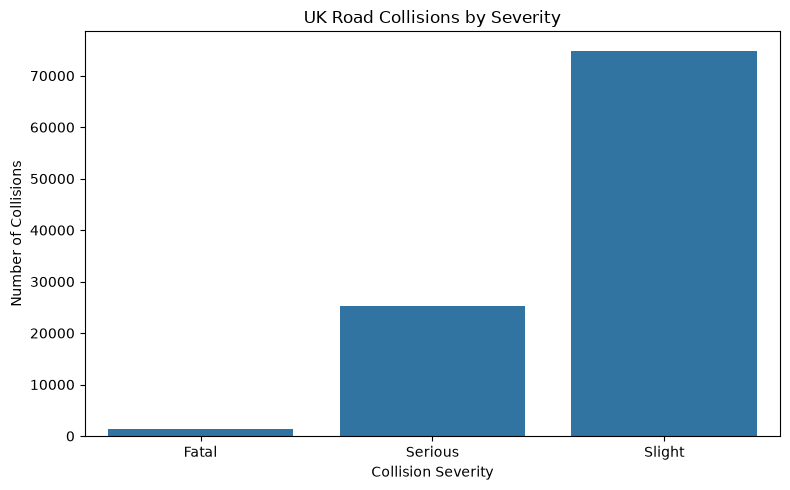

In [283]:
severity_counts = (
    collisions["severity_label"]
    .value_counts()
    .reindex(["Fatal", "Serious", "Slight"])
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=severity_counts.index,
    y=severity_counts.values
)

plt.title("UK Road Collisions by Severity")
plt.xlabel("Collision Severity")
plt.ylabel("Number of Collisions")

plt.tight_layout()
plt.show()

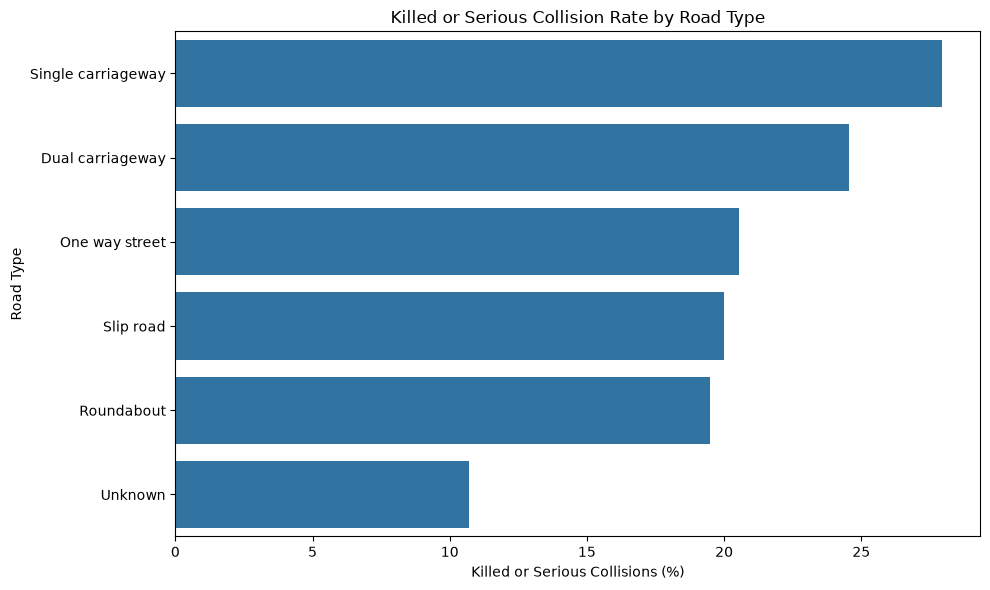

In [284]:
road_plot = (
    road_type_severity["killed_or_serious_percent"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=road_plot.values,
    y=road_plot.index
)

plt.title("Killed or Serious Collision Rate by Road Type")
plt.xlabel("Killed or Serious Collisions (%)")
plt.ylabel("Road Type")

plt.tight_layout()
plt.show()

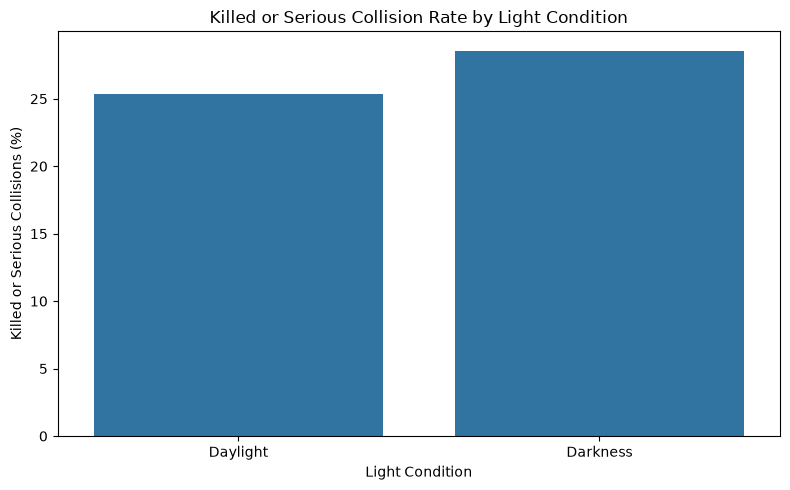

In [285]:
light_plot = (
    light_severity.loc[
        ["Daylight", "Darkness"],
        "killed_or_serious_percent"
    ]
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=light_plot.index,
    y=light_plot.values
)

plt.title("Killed or Serious Collision Rate by Light Condition")
plt.xlabel("Light Condition")
plt.ylabel("Killed or Serious Collisions (%)")

plt.tight_layout()
plt.show()

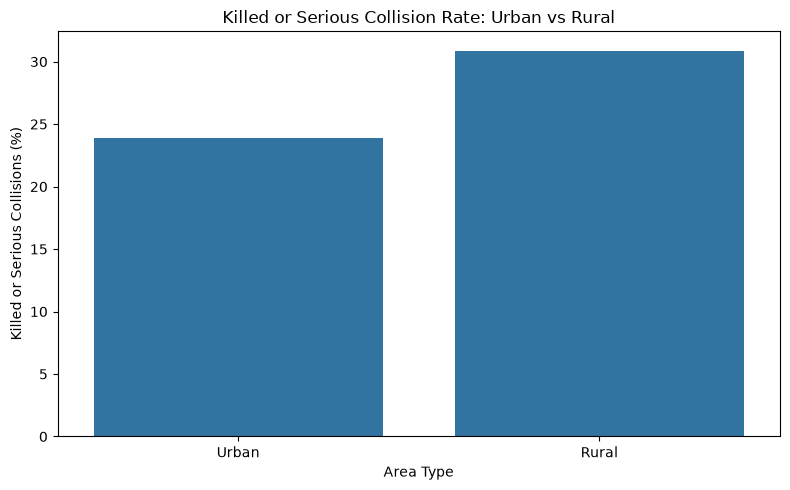

In [286]:
area_plot = (
    area_severity.loc[
        ["Urban", "Rural"],
        "killed_or_serious_percent"
    ]
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=area_plot.index,
    y=area_plot.values
)

plt.title("Killed or Serious Collision Rate: Urban vs Rural")
plt.xlabel("Area Type")
plt.ylabel("Killed or Serious Collisions (%)")

plt.tight_layout()
plt.show()

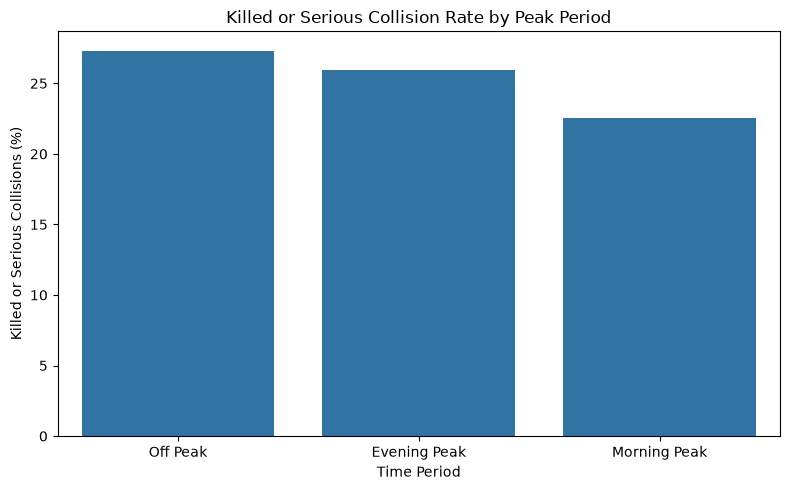

In [287]:
peak_plot = (
    peak_severity["killed_or_serious_percent"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=peak_plot.index,
    y=peak_plot.values
)

plt.title("Killed or Serious Collision Rate by Peak Period")
plt.xlabel("Time Period")
plt.ylabel("Killed or Serious Collisions (%)")

plt.tight_layout()
plt.show()

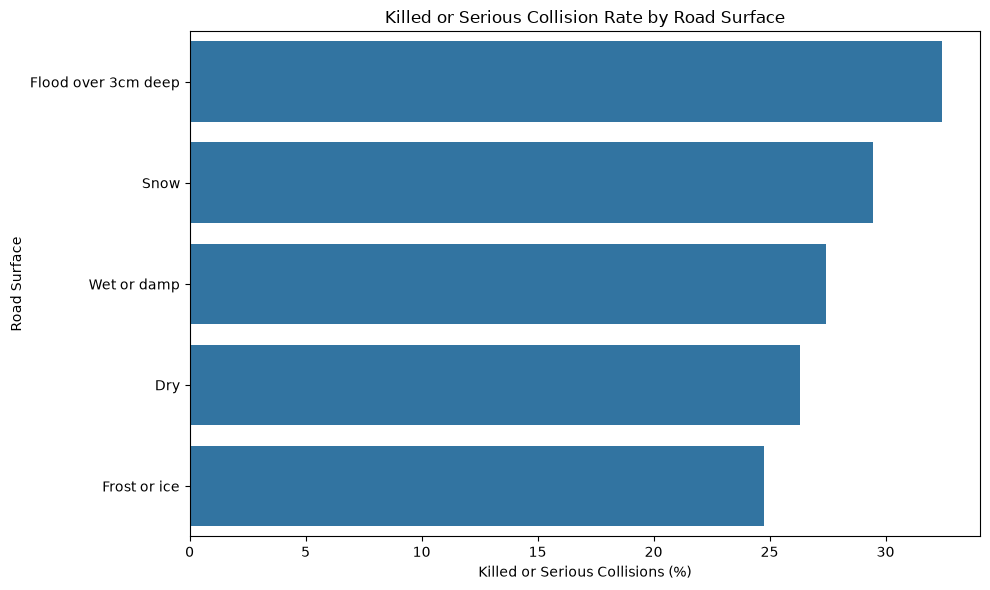

In [288]:
surface_plot = (
    surface_severity
    .drop(
        index=["Unknown", "Data missing or out of range"],
        errors="ignore"
    )["killed_or_serious_percent"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=surface_plot.values,
    y=surface_plot.index
)

plt.title("Killed or Serious Collision Rate by Road Surface")
plt.xlabel("Killed or Serious Collisions (%)")
plt.ylabel("Road Surface")

plt.tight_layout()
plt.show()

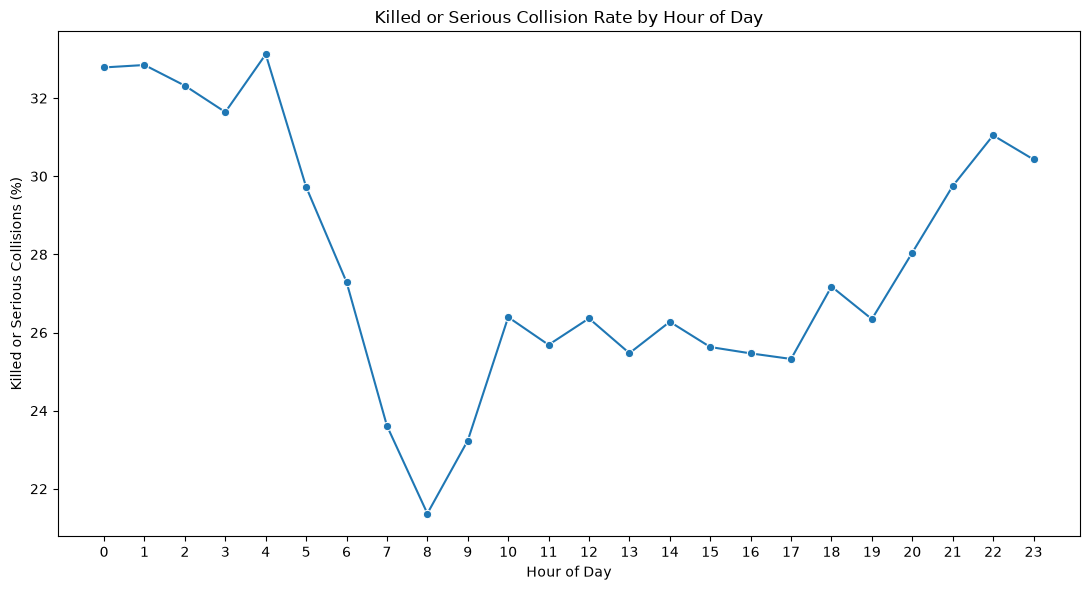

In [289]:
hour_severity = pd.crosstab(
    collisions["hour"],
    collisions["severity_label"],
    normalize="index"
).mul(100)

hour_severity["killed_or_serious_percent"] = (
    hour_severity["Fatal"] +
    hour_severity["Serious"]
)

plt.figure(figsize=(11, 6))

sns.lineplot(
    x=hour_severity.index,
    y=hour_severity["killed_or_serious_percent"],
    marker="o"
)

plt.title("Killed or Serious Collision Rate by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Killed or Serious Collisions (%)")
plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()

In [290]:
daytype_severity = pd.crosstab(
    collisions["day_type"],
    collisions["severity_label"],
    normalize="index"
).mul(100).round(2)

daytype_severity["killed_or_serious_percent"] = (
    daytype_severity["Fatal"] +
    daytype_severity["Serious"]
)

daytype_severity[
    ["Fatal", "Serious", "Slight", "killed_or_serious_percent"]
]

severity_label,Fatal,Serious,Slight,killed_or_serious_percent
day_type,,,,
Weekday,1.32,24.21,74.47,25.53
Weekend,1.79,26.67,71.54,28.46


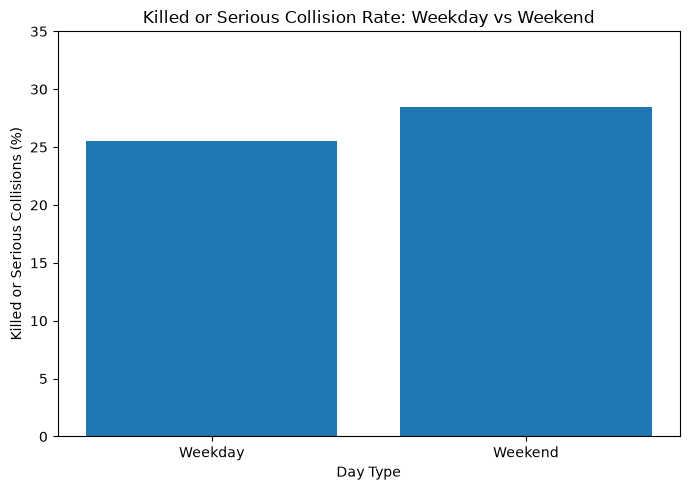

In [291]:
plot_data = daytype_severity.loc[
    ["Weekday", "Weekend"],
    "killed_or_serious_percent"
]

plt.figure(figsize=(7, 5))

plt.bar(
    plot_data.index,
    plot_data.values
)

plt.title("Killed or Serious Collision Rate: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Killed or Serious Collisions (%)")

plt.ylim(0, 35)

plt.tight_layout()
plt.show()

In [292]:
print("VEHICLE DATASET OVERVIEW")
print("------------------------")

print("Total vehicle records:", len(vehicles))
print("Columns:", vehicles.shape[1])

print("\nAvailable columns:")
print(vehicles.columns.tolist())

VEHICLE DATASET OVERVIEW
------------------------
Total vehicle records: 183948
Columns: 36

Available columns:
['collision_index', 'collision_year', 'collision_ref_no', 'vehicle_reference', 'vehicle_type', 'towing_and_articulation', 'vehicle_manoeuvre_historic', 'vehicle_manoeuvre', 'vehicle_direction_from', 'vehicle_direction_to', 'vehicle_location_restricted_lane_historic', 'vehicle_location_restricted_lane', 'junction_location', 'skidding_and_overturning', 'hit_object_in_carriageway', 'vehicle_leaving_carriageway', 'hit_object_off_carriageway', 'first_point_of_impact', 'vehicle_left_hand_drive', 'journey_purpose_of_driver_historic', 'journey_purpose_of_driver', 'sex_of_driver', 'age_of_driver', 'age_band_of_driver', 'engine_capacity_cc', 'propulsion_code', 'age_of_vehicle', 'generic_make_model', 'driver_imd_decile', 'lsoa_of_driver', 'escooter_flag', 'driver_distance_banding', 'age_of_driver_clean', 'driver_age_group', 'driver_sex_label', 'vehicle_type_label']


In [293]:
important_vehicle_columns = [
    "vehicle_type",
    "sex_of_driver",
    "age_of_driver",
    "age_of_driver_clean",
    "driver_age_group",
    "engine_capacity_cc",
    "age_of_vehicle"
]

for column in important_vehicle_columns:
    if column in vehicles.columns:
        print(f"{column}: FOUND")
    else:
        print(f"{column}: NOT FOUND")

vehicle_type: FOUND
sex_of_driver: FOUND
age_of_driver: FOUND
age_of_driver_clean: FOUND
driver_age_group: FOUND
engine_capacity_cc: FOUND
age_of_vehicle: FOUND


In [294]:
vehicle_analysis = vehicles.merge(
    collisions[
        ["collision_index", "severity_label"]
    ],
    on="collision_index",
    how="left"
)

print("Vehicle analysis dataset created!")

print("Vehicle rows:", len(vehicle_analysis))
print(
    "Missing severity:",
    vehicle_analysis["severity_label"].isna().sum()
)

print(
    "\nColumns used:"
)
print(
    vehicle_analysis[
        [
            "collision_index",
            "driver_age_group",
            "severity_label"
        ]
    ].head()
)

Vehicle analysis dataset created!
Vehicle rows: 183948
Missing severity: 0

Columns used:
  collision_index driver_age_group severity_label
0   2025552501020            16-19         Slight
1   2025221557045            16-19         Slight
2   2025221551102            16-19         Slight
3   2025161606443            16-19         Slight
4   2025031672722            25-34         Slight


In [295]:
age_severity = pd.crosstab(
    vehicle_analysis["driver_age_group"],
    vehicle_analysis["severity_label"],
    normalize="index"
).mul(100).round(2)

age_severity["killed_or_serious_percent"] = (
    age_severity["Fatal"] +
    age_severity["Serious"]
)

age_severity[
    ["Fatal", "Serious", "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,Slight,killed_or_serious_percent
driver_age_group,,,,
75+,2.84,29.50,67.66,32.34
65-74,2.26,29.12,68.63,31.38
16-19,1.61,29.07,69.32,30.68
55-64,1.93,27.02,71.05,28.95
0-15,0.64,25.85,73.51,26.49
20-24,1.38,24.74,73.87,26.12
45-54,1.41,24.17,74.42,25.58
35-44,1.42,23.36,75.22,24.78
25-34,1.26,23.15,75.59,24.41


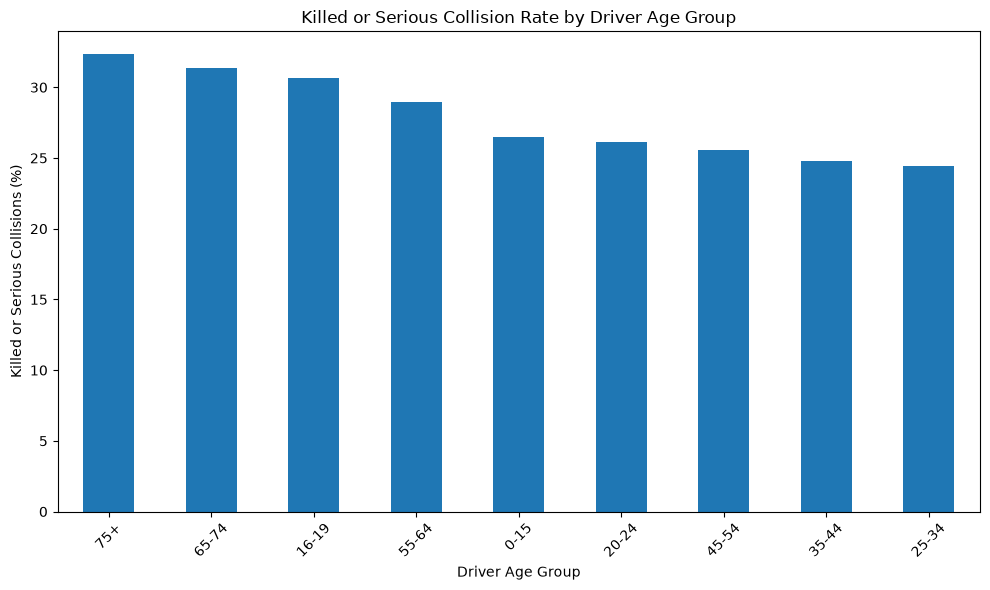

In [296]:
age_plot = (
    age_severity["killed_or_serious_percent"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

age_plot.plot(kind="bar")

plt.title("Killed or Serious Collision Rate by Driver Age Group")
plt.xlabel("Driver Age Group")
plt.ylabel("Killed or Serious Collisions (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [297]:
print("Driver sex codes:")

print(
    vehicles["sex_of_driver"]
    .value_counts(dropna=False)
    .sort_index()
)

Driver sex codes:
sex_of_driver
-1      4307
 1    112413
 2     47045
 3     20183
Name: count, dtype: int64


In [298]:
sex_severity = pd.crosstab(
    vehicle_analysis["sex_of_driver"],
    vehicle_analysis["severity_label"],
    normalize="index"
).mul(100).round(2)

sex_severity["killed_or_serious_percent"] = (
    sex_severity["Fatal"] +
    sex_severity["Serious"]
)

sex_severity[
    ["Fatal", "Serious", "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,Slight,killed_or_serious_percent
sex_of_driver,,,,
-1,1.25,29.65,69.10,30.90
1,1.78,25.95,72.27,27.73
2,0.97,22.08,76.95,23.05
3,0.24,15.41,84.35,15.65


In [299]:
print("Vehicle type codes:")

print(
    vehicles["vehicle_type"]
    .value_counts(dropna=False)
    .sort_index()
)

Vehicle type codes:
vehicle_type
-1          9
 1      17021
 2        813
 3       7876
 4       1792
 5       4976
 8       3614
 9     123212
 10       296
 11      3023
 16        78
 17       357
 18        28
 19     12555
 20       884
 21      2633
 22       346
 23       602
 33      1469
 90       770
 97       636
 98       673
 99       285
Name: count, dtype: int64


In [300]:
vehicle_type_severity = pd.crosstab(
    vehicle_analysis["vehicle_type"],
    vehicle_analysis["severity_label"],
    normalize="index"
).mul(100).round(2)

vehicle_type_severity["killed_or_serious_percent"] = (
    vehicle_type_severity["Fatal"] +
    vehicle_type_severity["Serious"]
)

vehicle_type_severity[
    ["Fatal", "Serious", "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,Fatal,Serious,Slight,killed_or_serious_percent
vehicle_type,,,,
5,5.77,48.07,46.16,53.84
18,7.14,42.86,50.00,50.00
23,1.33,45.35,53.32,46.68
4,2.12,40.85,57.03,42.97
97,1.73,40.41,57.86,42.14
17,6.72,30.81,62.46,37.53
33,0.61,34.38,65.01,34.99
90,3.77,30.13,66.10,33.90
-1,0.00,33.33,66.67,33.33


In [301]:
vehicle_type_counts = (
    vehicles["vehicle_type"]
    .value_counts()
    .rename("vehicle_count")
)

vehicle_type_summary = (
    vehicle_type_severity
    .join(vehicle_type_counts)
)

vehicle_type_summary[
    ["vehicle_count", "Fatal", "Serious",
     "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

,vehicle_count,Fatal,Serious,Slight,killed_or_serious_percent
vehicle_type,,,,,
5,4976,5.77,48.07,46.16,53.84
18,28,7.14,42.86,50.00,50.00
23,602,1.33,45.35,53.32,46.68
4,1792,2.12,40.85,57.03,42.97
97,636,1.73,40.41,57.86,42.14
17,357,6.72,30.81,62.46,37.53
33,1469,0.61,34.38,65.01,34.99
90,770,3.77,30.13,66.10,33.90
-1,9,0.00,33.33,66.67,33.33


In [302]:
vehicle_type_reliable = vehicle_type_summary[
    vehicle_type_summary["vehicle_count"] >= 500
].copy()

vehicle_type_reliable[
    ["vehicle_count", "Fatal", "Serious",
     "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

,vehicle_count,Fatal,Serious,Slight,killed_or_serious_percent
vehicle_type,,,,,
5,4976,5.77,48.07,46.16,53.84
23,602,1.33,45.35,53.32,46.68
4,1792,2.12,40.85,57.03,42.97
97,636,1.73,40.41,57.86,42.14
33,1469,0.61,34.38,65.01,34.99
90,770,3.77,30.13,66.10,33.90
21,2633,6.27,24.80,68.93,31.07
3,7876,0.93,27.48,71.60,28.41
1,17021,0.53,27.11,72.36,27.64


In [305]:
vehicle_type_map = {
    1: "Pedal cycle",
    2: "Motorcycle ≤50cc",
    3: "Motorcycle 51-125cc",
    4: "Motorcycle 126-500cc",
    5: "Motorcycle >500cc",
    8: "Taxi / Private hire",
    9: "Car",
    10: "Minibus",
    11: "Bus / Coach",
    16: "Ridden horse",
    17: "Agricultural vehicle",
    18: "Tram / Light rail",
    19: "Van / Goods ≤3.5t",
    20: "Goods 3.5-7.5t",
    21: "Goods ≥7.5t",
    22: "Mobility scooter",
    23: "Electric motorcycle",
    33: "Personal powered transporter",
    90: "Other vehicle",
    97: "Motorcycle - cc unknown",
    98: "Goods vehicle - weight unknown",
    99: "Unknown"
}

vehicle_type_filtered = vehicle_type_filtered.copy()

vehicle_type_filtered["vehicle_name"] = (
    vehicle_type_filtered.index.map(vehicle_type_map)
)

vehicle_type_filtered[
    ["vehicle_name", "vehicle_count", "killed_or_serious_percent"]
]

NameError: name 'vehicle_type_filtered' is not defined

In [ ]:
# Recreate vehicle type analysis table

vehicle_type_severity = pd.crosstab(
    vehicle_analysis["vehicle_type"],
    vehicle_analysis["severity_label"],
    normalize="index"
).mul(100).round(2)

vehicle_type_severity["killed_or_serious_percent"] = (
    vehicle_type_severity["Fatal"] +
    vehicle_type_severity["Serious"]
)

# Add sample size
vehicle_type_severity["vehicle_count"] = (
    vehicle_analysis["vehicle_type"].value_counts()
)

# Keep vehicle types with at least 500 records
vehicle_type_filtered = vehicle_type_severity[
    vehicle_type_severity["vehicle_count"] >= 500
].copy()

# Add readable vehicle names
vehicle_type_filtered["vehicle_name"] = (
    vehicle_type_filtered.index.map(vehicle_type_map)
)

# Show result
vehicle_type_filtered[
    ["vehicle_name", "vehicle_count", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

severity_label,vehicle_name,vehicle_count,killed_or_serious_percent
vehicle_type,,,
5,Motorcycle >500cc,4976,53.84
23,Electric motorcycle,602,46.68
4,Motorcycle 126-500cc,1792,42.97
97,Motorcycle - cc unknown,636,42.14
33,Personal powered transporter,1469,34.99
90,Other vehicle,770,33.90
21,Goods ≥7.5t,2633,31.07
3,Motorcycle 51-125cc,7876,28.41
1,Pedal cycle,17021,27.64


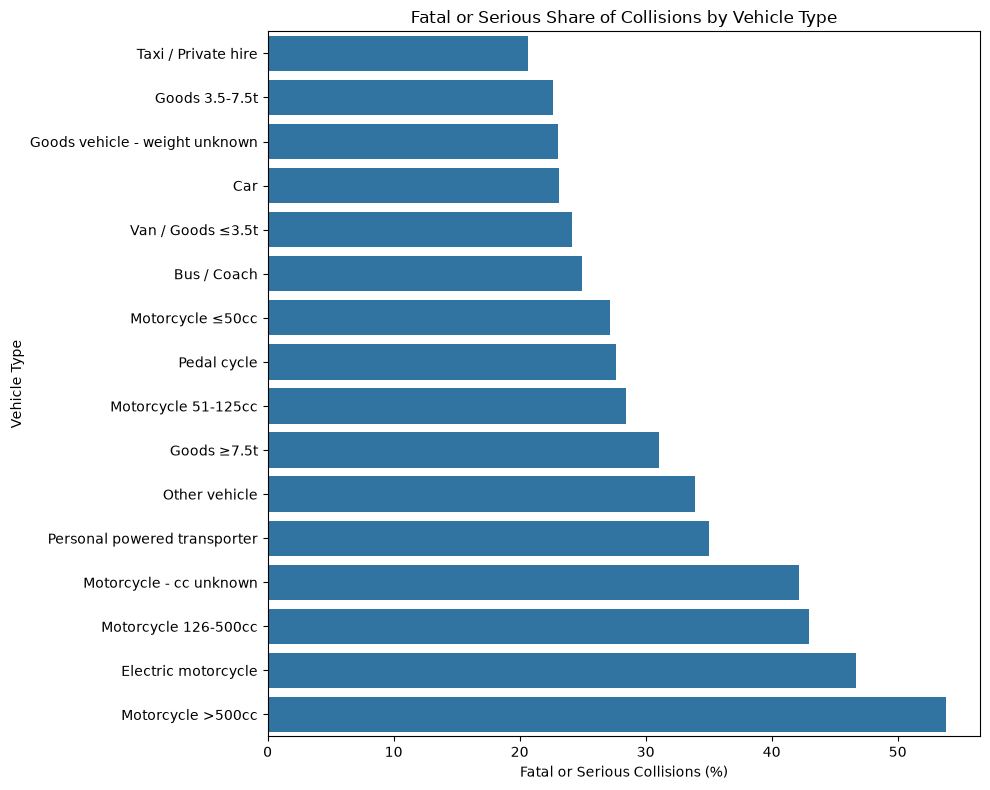

In [ ]:
vehicle_plot = vehicle_type_filtered.sort_values(
    "killed_or_serious_percent",
    ascending=True
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=vehicle_plot,
    x="killed_or_serious_percent",
    y="vehicle_name"
)

plt.title(
    "Fatal or Serious Share of Collisions by Vehicle Type"
)
plt.xlabel("Fatal or Serious Collisions (%)")
plt.ylabel("Vehicle Type")

plt.tight_layout()
plt.show()

In [ ]:
print("CASUALTY DATASET OVERVIEW")
print("-" * 40)

print("Total casualty records:", len(casualties))
print("Number of columns:", casualties.shape[1])

print("\nAvailable columns:")
print(casualties.columns.tolist())

CASUALTY DATASET OVERVIEW
----------------------------------------
Total casualty records: 127883
Number of columns: 29

Available columns:
['collision_index', 'collision_year', 'collision_ref_no', 'vehicle_reference', 'casualty_reference', 'casualty_class', 'sex_of_casualty', 'age_of_casualty', 'age_band_of_casualty', 'casualty_severity', 'pedestrian_location', 'pedestrian_movement', 'car_passenger', 'bus_or_coach_passenger', 'pedestrian_road_maintenance_worker', 'casualty_type', 'casualty_imd_decile', 'lsoa_of_casualty', 'enhanced_casualty_severity', 'casualty_injury_based', 'casualty_adjusted_severity_serious', 'casualty_adjusted_severity_slight', 'casualty_distance_banding', 'escooter_flag', 'age_of_casualty_clean', 'casualty_age_group', 'casualty_severity_label', 'casualty_class_label', 'casualty_sex_label']


In [ ]:
important_casualty_columns = [
    "casualty_class",
    "sex_of_casualty",
    "age_of_casualty",
    "age_of_casualty_clean",
    "casualty_age_group",
    "casualty_severity",
    "casualty_type",
    "pedestrian_location",
    "pedestrian_movement"
]

for column in important_casualty_columns:
    if column in casualties.columns:
        print(f"{column}: FOUND")
    else:
        print(f"{column}: NOT FOUND")

casualty_class: FOUND
sex_of_casualty: FOUND
age_of_casualty: FOUND
age_of_casualty_clean: FOUND
casualty_age_group: FOUND
casualty_severity: FOUND
casualty_type: FOUND
pedestrian_location: FOUND
pedestrian_movement: FOUND


In [ ]:
print("Casualty severity codes:")
print(
    casualties["casualty_severity"]
    .value_counts(dropna=False)
    .sort_index()
)

Casualty severity codes:
casualty_severity
1     1538
2    27758
3    98587
Name: count, dtype: int64


In [ ]:
casualty_severity_map = {
    1: "Fatal",
    2: "Serious",
    3: "Slight"
}

casualties["casualty_severity_label"] = (
    casualties["casualty_severity"]
    .map(casualty_severity_map)
)

print(
    casualties["casualty_severity_label"]
    .value_counts()
)

print(
    "\nUnmapped values:",
    casualties["casualty_severity_label"].isna().sum()
)

casualty_severity_label
Slight     98587
Serious    27758
Fatal       1538
Name: count, dtype: int64

Unmapped values: 0


In [ ]:
casualty_age_severity = pd.crosstab(
    casualties["casualty_age_group"],
    casualties["casualty_severity_label"],
    normalize="index"
).mul(100).round(2)

casualty_age_severity["killed_or_serious_percent"] = (
    casualty_age_severity["Fatal"] +
    casualty_age_severity["Serious"]
)

casualty_age_severity[
    ["Fatal", "Serious", "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

casualty_severity_label,Fatal,Serious,Slight,killed_or_serious_percent
casualty_age_group,,,,
75+,3.98,30.99,65.04,34.97
65-74,2.18,28.70,69.12,30.88
16-19,1.22,25.42,73.36,26.64
55-64,1.55,24.82,73.63,26.37
20-24,1.04,21.23,77.73,22.27
45-54,1.09,20.67,78.24,21.76
0-15,0.35,20.10,79.55,20.45
35-44,0.91,18.93,80.16,19.84
25-34,0.83,19.01,80.16,19.84


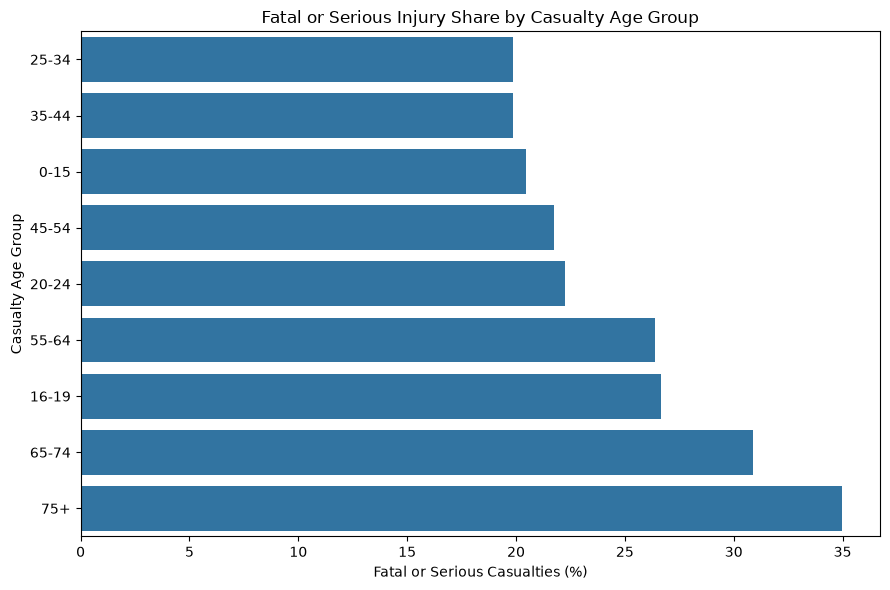

In [ ]:
age_plot = (
    casualty_age_severity
    .reset_index()
    .sort_values("killed_or_serious_percent", ascending=True)
)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=age_plot,
    x="killed_or_serious_percent",
    y="casualty_age_group"
)

plt.title("Fatal or Serious Injury Share by Casualty Age Group")
plt.xlabel("Fatal or Serious Casualties (%)")
plt.ylabel("Casualty Age Group")

plt.tight_layout()
plt.show()

In [ ]:
print("Sex of casualty codes:")

print(
    casualties["sex_of_casualty"]
    .value_counts(dropna=False)
    .sort_index()
)

Sex of casualty codes:
sex_of_casualty
-1     1320
 1    77637
 2    48874
 9       52
Name: count, dtype: int64


In [ ]:
sex_casualty_severity = pd.crosstab(
    casualties["sex_of_casualty"],
    casualties["casualty_severity_label"],
    normalize="index"
).mul(100).round(2)

sex_casualty_severity["killed_or_serious_percent"] = (
    sex_casualty_severity["Fatal"] +
    sex_casualty_severity["Serious"]
)

sex_casualty_severity[
    ["Fatal", "Serious", "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

casualty_severity_label,Fatal,Serious,Slight,killed_or_serious_percent
sex_of_casualty,,,,
1,1.53,23.97,74.50,25.50
2,0.72,18.53,80.76,19.25
9,0.00,7.69,92.31,7.69
-1,0.00,6.52,93.48,6.52


In [ ]:
sex_map = {
    1: "Male",
    2: "Female",
    9: "Unknown",
    -1: "Missing / Out of range"
}

casualties["sex_label"] = (
    casualties["sex_of_casualty"].map(sex_map)
)

print(
    casualties["sex_label"]
    .value_counts(dropna=False)
)

sex_label
Male                      77637
Female                    48874
Missing / Out of range     1320
Unknown                      52
Name: count, dtype: int64


casualty_severity_label  Fatal  Serious  Slight  killed_or_serious_percent
sex_label                                                                 
Female                    0.72    18.53   80.76                      19.25
Male                      1.53    23.97   74.50                      25.50


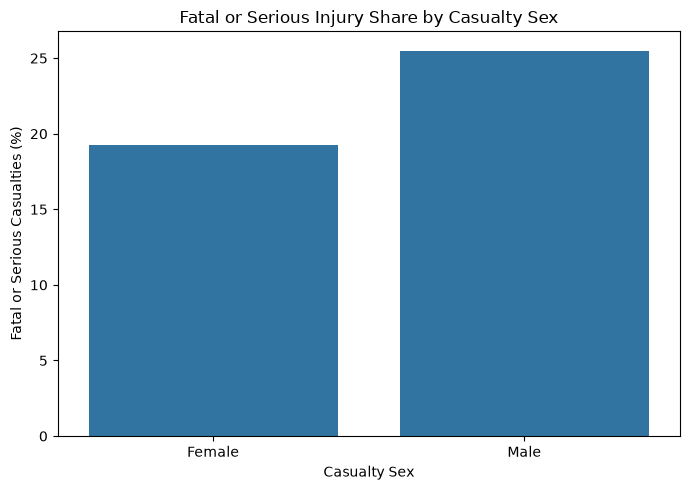

In [ ]:
sex_plot_data = casualties[
    casualties["sex_label"].isin(["Male", "Female"])
].copy()

sex_summary = pd.crosstab(
    sex_plot_data["sex_label"],
    sex_plot_data["casualty_severity_label"],
    normalize="index"
).mul(100).round(2)

sex_summary["killed_or_serious_percent"] = (
    sex_summary["Fatal"] +
    sex_summary["Serious"]
)

print(sex_summary)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=sex_summary.reset_index(),
    x="sex_label",
    y="killed_or_serious_percent"
)

plt.title("Fatal or Serious Injury Share by Casualty Sex")
plt.xlabel("Casualty Sex")
plt.ylabel("Fatal or Serious Casualties (%)")

plt.tight_layout()
plt.show()

In [ ]:
print("Casualty class codes:")

print(
    casualties["casualty_class"]
    .value_counts(dropna=False)
    .sort_index()
)

Casualty class codes:
casualty_class
1    83976
2    23929
3    19978
Name: count, dtype: int64


In [ ]:
casualty_class_map = {
    1: "Driver / Rider",
    2: "Passenger",
    3: "Pedestrian"
}

casualties["casualty_class_label"] = (
    casualties["casualty_class"].map(casualty_class_map)
)

class_severity = pd.crosstab(
    casualties["casualty_class_label"],
    casualties["casualty_severity_label"],
    normalize="index"
).mul(100).round(2)

class_severity["killed_or_serious_percent"] = (
    class_severity["Fatal"] +
    class_severity["Serious"]
)

class_severity[
    ["Fatal", "Serious", "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

casualty_severity_label,Fatal,Serious,Slight,killed_or_serious_percent
casualty_class_label,,,,
Pedestrian,1.82,29.19,68.99,31.01
Driver / Rider,1.14,21.17,77.68,22.31
Passenger,0.89,17.33,81.78,18.22


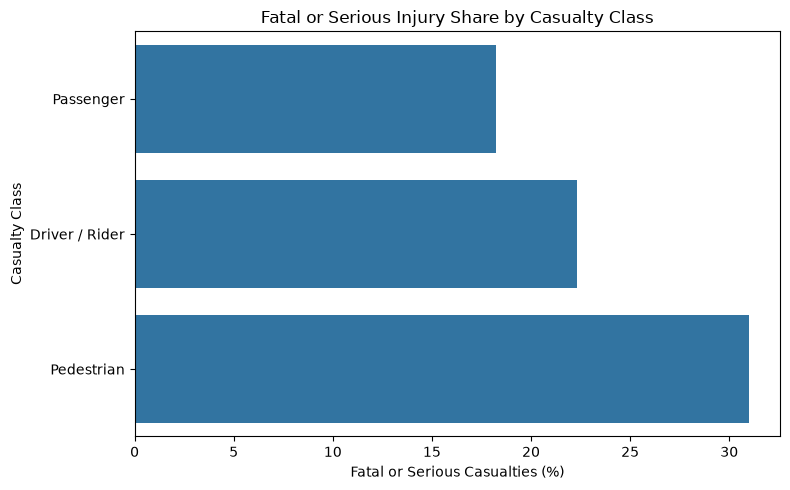

In [ ]:
class_plot = (
    class_severity
    .reset_index()
    .sort_values("killed_or_serious_percent", ascending=True)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=class_plot,
    x="killed_or_serious_percent",
    y="casualty_class_label"
)

plt.title("Fatal or Serious Injury Share by Casualty Class")
plt.xlabel("Fatal or Serious Casualties (%)")
plt.ylabel("Casualty Class")

plt.tight_layout()
plt.show()

In [ ]:
print("Casualty type codes:")

print(
    casualties["casualty_type"]
    .value_counts(dropna=False)
    .sort_index()
)

Casualty type codes:
casualty_type
-1         2
 0     19978
 1     16042
 2       732
 3      7320
 4      1662
 5      4882
 8      1599
 9     65921
 10      233
 11     2036
 16       65
 17       78
 18       16
 19     3931
 20      202
 21      401
 22      271
 23      481
 33     1227
 90      305
 97      370
 98      114
 99       15
Name: count, dtype: int64


In [ ]:
casualty_type_map = {
    0: "Pedestrian",
    1: "Pedal cycle",
    2: "Motorcycle ≤50cc",
    3: "Motorcycle 51-125cc",
    4: "Motorcycle 126-500cc",
    5: "Motorcycle >500cc",
    8: "Taxi / Private hire",
    9: "Car occupant",
    10: "Minibus occupant",
    11: "Bus / Coach occupant",
    16: "Horse rider",
    17: "Agricultural vehicle occupant",
    18: "Tram / Light rail occupant",
    19: "Van / Goods ≤3.5t occupant",
    20: "Goods 3.5-7.5t occupant",
    21: "Goods ≥7.5t occupant",
    22: "Mobility scooter rider",
    23: "Electric motorcycle rider",
    33: "Personal powered transporter",
    90: "Other vehicle occupant",
    97: "Motorcycle - cc unknown",
    98: "Goods vehicle - weight unknown",
    99: "Unknown",
    -1: "Missing / Out of range"
}

casualties["casualty_type_label"] = (
    casualties["casualty_type"].map(casualty_type_map)
)

print(
    casualties[
        ["casualty_type", "casualty_type_label"]
    ]
    .value_counts()
    .sort_index()
)

print(
    "\nUnmapped records:",
    casualties["casualty_type_label"].isna().sum()
)

casualty_type  casualty_type_label           
-1             Missing / Out of range                2
 0             Pedestrian                        19978
 1             Pedal cycle                       16042
 2             Motorcycle ≤50cc                    732
 3             Motorcycle 51-125cc                7320
 4             Motorcycle 126-500cc               1662
 5             Motorcycle >500cc                  4882
 8             Taxi / Private hire                1599
 9             Car occupant                      65921
 10            Minibus occupant                    233
 11            Bus / Coach occupant               2036
 16            Horse rider                          65
 17            Agricultural vehicle occupant        78
 18            Tram / Light rail occupant           16
 19            Van / Goods ≤3.5t occupant         3931
 20            Goods 3.5-7.5t occupant             202
 21            Goods ≥7.5t occupant                401
 22            Mobi

In [ ]:
casualty_type_severity = pd.crosstab(
    casualties["casualty_type_label"],
    casualties["casualty_severity_label"],
    normalize="index"
).mul(100).round(2)

casualty_type_severity["killed_or_serious_percent"] = (
    casualty_type_severity["Fatal"] +
    casualty_type_severity["Serious"]
)

# Add number of casualty records
casualty_type_counts = (
    casualties["casualty_type_label"]
    .value_counts()
    .rename("casualty_count")
)

casualty_type_summary = casualty_type_severity.join(
    casualty_type_counts
)

# Keep categories with at least 500 casualties
casualty_type_reliable = casualty_type_summary[
    casualty_type_summary["casualty_count"] >= 500
].copy()

casualty_type_reliable[
    ["casualty_count", "Fatal", "Serious",
     "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

,casualty_count,Fatal,Serious,Slight,killed_or_serious_percent
casualty_type_label,,,,,
Motorcycle >500cc,4882,5.41,47.52,47.07,52.93
Motorcycle 126-500cc,1662,2.29,41.34,56.38,43.63
Personal powered transporter,1227,0.81,35.21,63.98,36.02
Pedestrian,19978,1.82,29.19,68.99,31.01
Motorcycle ≤50cc,732,0.55,27.60,71.86,28.15
Motorcycle 51-125cc,7320,0.87,27.24,71.89,28.11
Pedal cycle,16042,0.49,26.33,73.18,26.82
Car occupant,65921,0.94,15.46,83.60,16.40
Van / Goods ≤3.5t occupant,3931,0.84,15.14,84.02,15.98


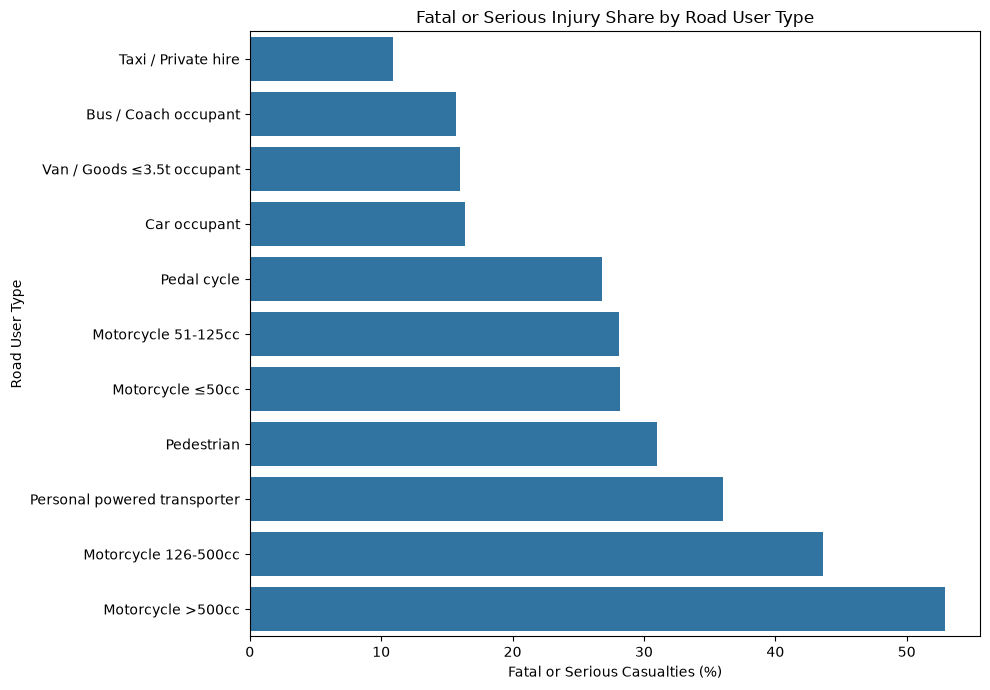

In [ ]:
casualty_type_plot = (
    casualty_type_reliable
    .reset_index()
    .sort_values("killed_or_serious_percent", ascending=True)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=casualty_type_plot,
    x="killed_or_serious_percent",
    y="casualty_type_label"
)

plt.title("Fatal or Serious Injury Share by Road User Type")
plt.xlabel("Fatal or Serious Casualties (%)")
plt.ylabel("Road User Type")

plt.tight_layout()
plt.show()

In [ ]:
print("Pedestrian location codes:")
print(
    casualties["pedestrian_location"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nPedestrian movement codes:")
print(
    casualties["pedestrian_movement"]
    .value_counts(dropna=False)
    .sort_index()
)

Pedestrian location codes:
pedestrian_location
-1         43
 0     107900
 1       3379
 2         79
 3         28
 4       1078
 5       7213
 6       2628
 7        109
 8       1462
 9       2106
 10      1858
Name: count, dtype: int64

Pedestrian movement codes:
pedestrian_movement
-1        41
 0    107899
 1      6322
 2       880
 3      4170
 4       519
 5      1026
 6       139
 7       739
 8       581
 9      5567
Name: count, dtype: int64


In [ ]:
pedestrians = casualties[
    casualties["casualty_type"] == 0
].copy()

print("PEDESTRIAN DATASET")
print("-" * 30)
print("Pedestrian casualties:", len(pedestrians))

print("\nPedestrian location codes:")
print(
    pedestrians["pedestrian_location"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nPedestrian movement codes:")
print(
    pedestrians["pedestrian_movement"]
    .value_counts(dropna=False)
    .sort_index()
)

PEDESTRIAN DATASET
------------------------------
Pedestrian casualties: 19978

Pedestrian location codes:
pedestrian_location
-1       43
 1     3378
 2       79
 3       28
 4     1078
 5     7213
 6     2628
 7      108
 8     1459
 9     2106
 10    1858
Name: count, dtype: int64

Pedestrian movement codes:
pedestrian_movement
-1      41
 1    6318
 2     880
 3    4168
 4     519
 5    1026
 6     139
 7     739
 8     581
 9    5567
Name: count, dtype: int64


In [ ]:
ped_location_severity = pd.crosstab(
    pedestrians["pedestrian_location"],
    pedestrians["casualty_severity_label"],
    normalize="index"
).mul(100).round(2)

ped_location_severity["killed_or_serious_percent"] = (
    ped_location_severity["Fatal"] +
    ped_location_severity["Serious"]
)

ped_location_severity[
    ["Fatal", "Serious", "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

casualty_severity_label,Fatal,Serious,Slight,killed_or_serious_percent
pedestrian_location,,,,
2,3.80,40.51,55.70,44.31
4,1.58,39.61,58.81,41.19
8,3.22,33.24,63.54,36.46
5,1.91,31.35,66.74,33.26
7,3.70,28.70,67.59,32.40
3,0.00,32.14,67.86,32.14
1,1.36,29.66,68.98,31.02
9,2.28,24.93,72.79,27.21
6,1.10,24.47,74.43,25.57


In [ ]:
ped_location_summary = ped_location_severity.copy()

ped_location_summary["pedestrian_count"] = (
    pedestrians["pedestrian_location"].value_counts()
)

ped_location_summary[
    ["pedestrian_count", "Fatal", "Serious",
     "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

casualty_severity_label,pedestrian_count,Fatal,Serious,Slight,killed_or_serious_percent
pedestrian_location,,,,,
2,79,3.80,40.51,55.70,44.31
4,1078,1.58,39.61,58.81,41.19
8,1459,3.22,33.24,63.54,36.46
5,7213,1.91,31.35,66.74,33.26
7,108,3.70,28.70,67.59,32.40
3,28,0.00,32.14,67.86,32.14
1,3378,1.36,29.66,68.98,31.02
9,2106,2.28,24.93,72.79,27.21
6,2628,1.10,24.47,74.43,25.57


In [ ]:
ped_location_reliable = ped_location_summary[
    ped_location_summary["pedestrian_count"] >= 500
].copy()

ped_location_reliable[
    ["pedestrian_count", "Fatal", "Serious",
     "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

casualty_severity_label,pedestrian_count,Fatal,Serious,Slight,killed_or_serious_percent
pedestrian_location,,,,,
4,1078,1.58,39.61,58.81,41.19
8,1459,3.22,33.24,63.54,36.46
5,7213,1.91,31.35,66.74,33.26
1,3378,1.36,29.66,68.98,31.02
9,2106,2.28,24.93,72.79,27.21
6,2628,1.10,24.47,74.43,25.57
10,1858,1.72,21.85,76.43,23.57


In [ ]:
pedestrian_location_map = {
    1: "Crossing on pedestrian crossing",
    2: "Crossing within zig-zag approach",
    3: "Crossing within zig-zag exit",
    4: "Crossing within 50m of crossing",
    5: "Crossing elsewhere",
    6: "On footway or verge",
    7: "On refuge / central island",
    8: "Centre of carriageway",
    9: "In carriageway, not crossing",
    10: "Unknown or other",
    -1: "Missing / Out of range"
}

ped_location_reliable["location_label"] = (
    ped_location_reliable.index.map(pedestrian_location_map)
)

ped_location_reliable[
    ["location_label", "pedestrian_count",
     "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

casualty_severity_label,location_label,pedestrian_count,killed_or_serious_percent
pedestrian_location,,,
4,Crossing within 50m of crossing,1078,41.19
8,Centre of carriageway,1459,36.46
5,Crossing elsewhere,7213,33.26
1,Crossing on pedestrian crossing,3378,31.02
9,"In carriageway, not crossing",2106,27.21
6,On footway or verge,2628,25.57
10,Unknown or other,1858,23.57


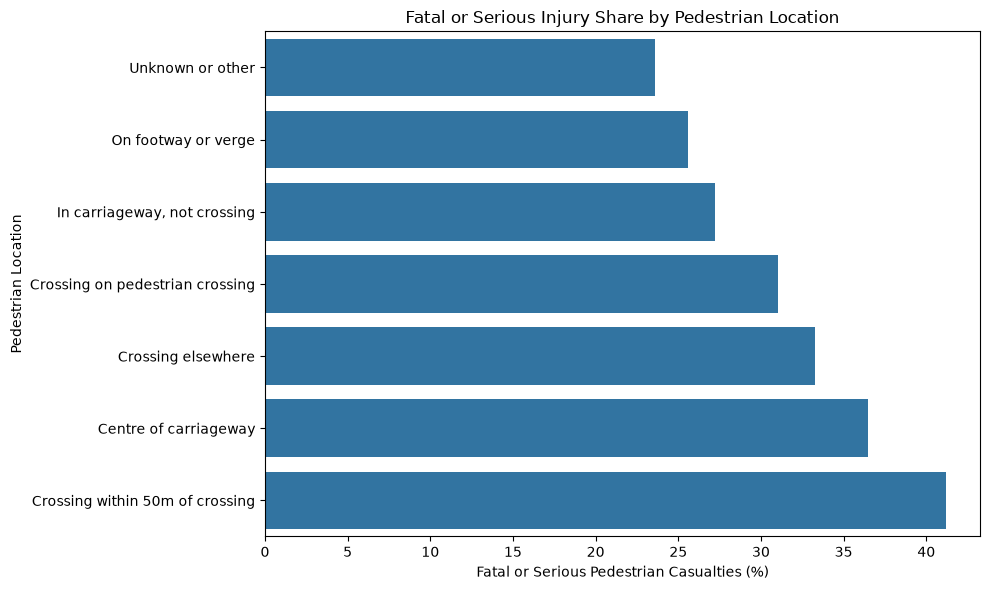

In [ ]:
ped_location_plot = (
    ped_location_reliable
    .sort_values("killed_or_serious_percent", ascending=True)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=ped_location_plot,
    x="killed_or_serious_percent",
    y="location_label"
)

plt.title("Fatal or Serious Injury Share by Pedestrian Location")
plt.xlabel("Fatal or Serious Pedestrian Casualties (%)")
plt.ylabel("Pedestrian Location")

plt.tight_layout()
plt.show()

In [306]:
ped_movement_severity = pd.crosstab(
    pedestrians["pedestrian_movement"],
    pedestrians["casualty_severity_label"],
    normalize="index"
).mul(100).round(2)

ped_movement_severity["killed_or_serious_percent"] = (
    ped_movement_severity["Fatal"] +
    ped_movement_severity["Serious"]
)

ped_movement_counts = (
    pedestrians["pedestrian_movement"]
    .value_counts()
    .rename("pedestrian_count")
)

ped_movement_summary = ped_movement_severity.join(
    ped_movement_counts
)

ped_movement_summary[
    ["pedestrian_count", "Fatal", "Serious",
     "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

NameError: name 'pedestrians' is not defined

In [ ]:
ped_movement_reliable = ped_movement_summary[
    ped_movement_summary["pedestrian_count"] >= 500
].copy()

ped_movement_reliable[
    ["pedestrian_count", "Fatal", "Serious",
     "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

NameError: name 'ped_movement_summary' is not defined

In [304]:
pedestrian_movement_map = {
    1: "Crossing from driver's nearside",
    2: "Crossing from nearside - masked",
    3: "Crossing from driver's offside",
    4: "Crossing from offside - masked",
    5: "In carriageway, stationary",
    6: "In carriageway, stationary - masked",
    7: "Walking along carriageway facing traffic",
    8: "Walking along carriageway back to traffic",
    9: "Unknown or other",
    -1: "Missing / Out of range"
}

ped_movement_reliable["movement_label"] = (
    ped_movement_reliable.index.map(pedestrian_movement_map)
)

ped_movement_reliable[
    ["movement_label", "pedestrian_count",
     "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

NameError: name 'ped_movement_reliable' is not defined

In [307]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_PATH = Path("../data/processed")

casualties = pd.read_csv(DATA_PATH / "casualties_clean.csv")

print("Casualties loaded:", casualties.shape)

required_columns = [
    "casualty_type",
    "casualty_severity",
    "pedestrian_location",
    "pedestrian_movement"
]

for column in required_columns:
    print(column, "->", column in casualties.columns)

Casualties loaded: (127883, 29)
casualty_type -> True
casualty_severity -> True
pedestrian_location -> True
pedestrian_movement -> True


In [308]:
# Recreate casualty severity labels
casualty_severity_map = {
    1: "Fatal",
    2: "Serious",
    3: "Slight"
}

casualties["casualty_severity_label"] = (
    casualties["casualty_severity"].map(casualty_severity_map)
)

# Create pedestrian-only dataset
pedestrians = casualties[
    casualties["casualty_type"] == 0
].copy()

print("Pedestrian casualties:", len(pedestrians))

print("\nSeverity counts:")
print(
    pedestrians["casualty_severity_label"].value_counts()
)

Pedestrian casualties: 19978

Severity counts:
casualty_severity_label
Slight     13783
Serious     5831
Fatal        364
Name: count, dtype: int64


In [309]:
# Pedestrian movement severity percentages
ped_movement_severity = pd.crosstab(
    pedestrians["pedestrian_movement"],
    pedestrians["casualty_severity_label"],
    normalize="index"
).mul(100).round(2)

ped_movement_severity["killed_or_serious_percent"] = (
    ped_movement_severity["Fatal"] +
    ped_movement_severity["Serious"]
)

# Number of pedestrians in each movement category
ped_movement_counts = (
    pedestrians["pedestrian_movement"]
    .value_counts()
    .rename("pedestrian_count")
)

# Combine percentages and counts
ped_movement_summary = ped_movement_severity.join(
    ped_movement_counts
)

# Keep categories with at least 500 casualties
ped_movement_reliable = ped_movement_summary[
    ped_movement_summary["pedestrian_count"] >= 500
].copy()

ped_movement_reliable[
    ["pedestrian_count", "Fatal", "Serious",
     "Slight", "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

,pedestrian_count,Fatal,Serious,Slight,killed_or_serious_percent
pedestrian_movement,,,,,
4,519,0.77,37.96,61.27,38.73
2,880,1.14,33.30,65.57,34.44
3,4168,2.14,32.25,65.62,34.39
1,6318,1.76,32.29,65.95,34.05
8,581,3.79,28.40,67.81,32.19
7,739,1.49,27.74,70.77,29.23
5,1026,2.92,26.22,70.86,29.14
9,5567,1.54,22.76,75.70,24.30


In [310]:
pedestrian_movement_map = {
    1: "Crossing from driver's nearside",
    2: "Crossing from nearside - masked",
    3: "Crossing from driver's offside",
    4: "Crossing from offside - masked",
    5: "In carriageway, stationary",
    6: "In carriageway, stationary - masked",
    7: "Walking along carriageway facing traffic",
    8: "Walking along carriageway back to traffic",
    9: "Unknown or other",
    -1: "Missing / Out of range"
}

ped_movement_reliable["movement_label"] = (
    ped_movement_reliable.index.map(pedestrian_movement_map)
)

ped_movement_reliable[
    ["movement_label", "pedestrian_count",
     "killed_or_serious_percent"]
].sort_values(
    "killed_or_serious_percent",
    ascending=False
)

,movement_label,pedestrian_count,killed_or_serious_percent
pedestrian_movement,,,
4,Crossing from offside - masked,519,38.73
2,Crossing from nearside - masked,880,34.44
3,Crossing from driver's offside,4168,34.39
1,Crossing from driver's nearside,6318,34.05
8,Walking along carriageway back to traffic,581,32.19
7,Walking along carriageway facing traffic,739,29.23
5,"In carriageway, stationary",1026,29.14
9,Unknown or other,5567,24.30


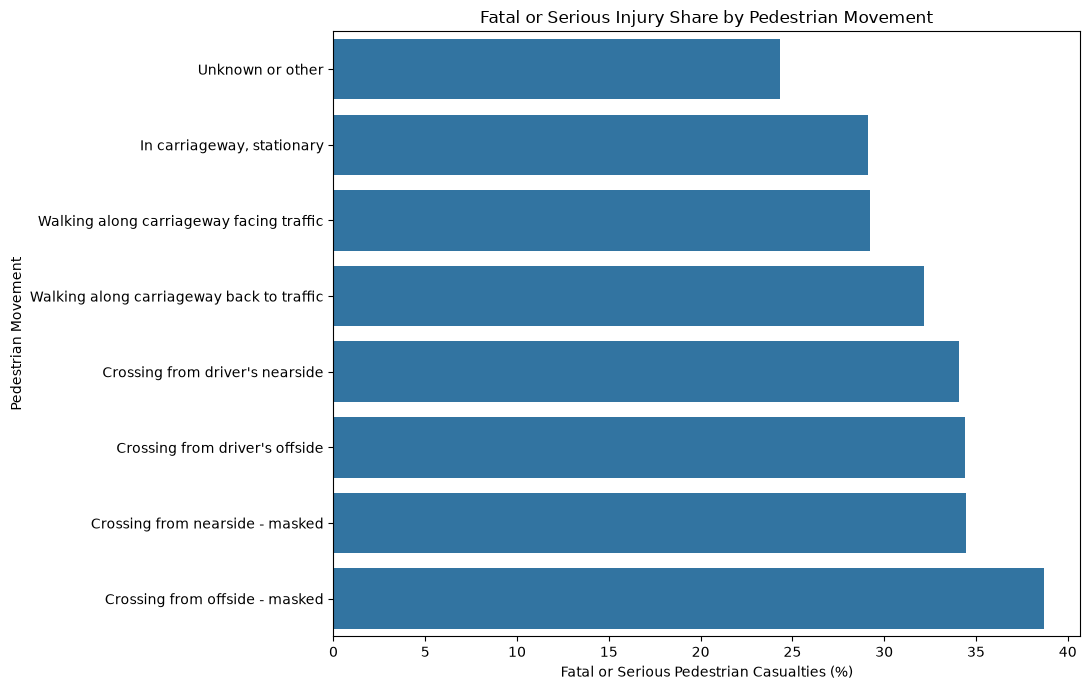

In [311]:
ped_movement_plot = (
    ped_movement_reliable
    .sort_values("killed_or_serious_percent", ascending=True)
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=ped_movement_plot,
    x="killed_or_serious_percent",
    y="movement_label"
)

plt.title("Fatal or Serious Injury Share by Pedestrian Movement")
plt.xlabel("Fatal or Serious Pedestrian Casualties (%)")
plt.ylabel("Pedestrian Movement")

plt.tight_layout()
plt.show()

## Key Exploratory Analysis Findings

### Collision Patterns
- Slight collisions account for the majority of recorded collisions.
- Rural collisions show a higher fatal-or-serious severity share than urban collisions.
- Weekend collisions have a higher fatal-or-serious share than weekday collisions.
- Late-night and early-morning collision hours show comparatively higher severity.
- Off-peak collisions show a higher fatal-or-serious share than morning and evening peak periods.

### Vehicle and Driver Patterns
- Older drivers, particularly those aged 75+, are involved in collisions with the highest fatal-or-serious severity share.
- Larger motorcycles (>500cc) are associated with a substantially higher fatal-or-serious collision share than cars and several other vehicle groups.
- Motorcycle categories generally show higher collision severity than car, van, bus and taxi/private-hire categories.

### Casualty Patterns
- Casualties aged 75+ have the highest fatal-or-serious injury share.
- Male casualties have a higher fatal-or-serious injury share than female casualties.
- Pedestrians have a higher fatal-or-serious injury share than drivers/riders and passengers.
- Motorcycle users, particularly those using motorcycles over 500cc, show high injury-severity shares.

### Pedestrian Patterns
- Pedestrians recorded as crossing within 50 metres of a pedestrian crossing show a relatively high fatal-or-serious injury share.
- Pedestrians located in the centre of the carriageway also show comparatively high injury severity.
- Crossing from the driver's offside while masked from view has the highest fatal-or-serious share among the pedestrian movement categories retained for analysis.
- Visibility and crossing circumstances therefore appear to be important dimensions for further road-safety analysis.

### Interpretation Note
These results describe patterns within recorded road collisions and casualties. Percentage comparisons represent severity shares within the observed data and should not be interpreted as exposure-adjusted accident or injury risk. The analysis identifies associations and does not establish causation.